# 04. Model Development and Evaluation

## 1. Research Objective

This notebook develops machine learning models to predict bank failure using quarterly financial data from the FDIC.

The main objectives are:
- Define the prediction target and eligible observations.
- Select financial and temporal predictors.
- Split the dataset chronologically to prevent look-ahead bias.
- Handle missing values using training data only.
- Train and evaluate classification models.
- Compare model performance and identify important predictors.

## 2. Data Source

The notebook uses the engineered dataset:

`data/processed/v3/bank_quarter_features_v3.parquet`

The target variable is `FINAL_LABEL`:
- 1: Bank failure within the defined prediction horizon.
- 0: No recorded bank failure within the prediction horizon.
- Null: Observation censored due to merger-related treatment; excluded from standard binary classification.

In [1]:
from pathlib import Path

import polars as pl
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve
)

# Identify project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define paths
feature_path = (
    project_root
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

figure_dir = project_root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Check dataset
assert feature_path.exists(), f"Dataset not found: {feature_path}"

print("Project root:", project_root)
print("Feature dataset:", feature_path)
print("Figure directory:", figure_dir)

Project root: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project
Feature dataset: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3.parquet
Figure directory: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures


In [2]:
features = pl.read_parquet(feature_path)

print("Dataset shape:", features.shape)

print("\nColumns:")
print(features.columns)

print("\nSchema:")
print(features.schema)

Dataset shape: (1663876, 36)

Columns:
['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG']

Schema:
Schema({'NCLNLS': Float64, 'LNATRES': Float64, 'ROA': Float64, 'REPDTE': String, 'ASSET': Int64, 'RBC1AAJ': Float64, 'CERT': Int64, 'NETINC': Float64, 'EQ': Float64, 'DEP': Float64, 'ID': String, 'REPORT_DATE': Date, 'REPORT_Q_INDEX': Int32, 'FIRST_FAILURE_DATE': Date, 'FAILURE_Q_INDEX': Int32, 'FAILURE_LABEL': Int8, 'IS_MERGER_CENSORED': Boolean, 'FINAL_LABEL': Int8, 'YEAR':

## 3. Target Variable Analysis

The target variable is `FINAL_LABEL`, which identifies whether a bank experiences failure within the defined prediction horizon.

Observations with null target values are excluded from standard binary classification because they are censored under the merger-related treatment.

This section examines the target distribution, class imbalance and eligible observations before model development.

In [3]:
# 1. Count observations by FINAL_LABEL
target_distribution = (
    features
    .group_by("FINAL_LABEL")
    .agg(pl.len().alias("COUNT"))
    .sort("FINAL_LABEL", nulls_last=True)
)

display(target_distribution)

# 2. Calculate total observations
total_rows = features.height

# 3. Count eligible and censored observations
eligible_rows = features.filter(
    pl.col("FINAL_LABEL").is_not_null()
).height

censored_rows = features.filter(
    pl.col("FINAL_LABEL").is_null()
).height

print(f"Total observations: {total_rows:,}")
print(f"Eligible observations: {eligible_rows:,}")
print(f"Censored observations: {censored_rows:,}")

print(f"Eligible rate: {eligible_rows / total_rows * 100:.2f}%")
print(f"Censored rate: {censored_rows / total_rows * 100:.2f}%")

# 4. Calculate failure rate among eligible observations
failure_count = features.filter(
    pl.col("FINAL_LABEL") == 1
).height

non_failure_count = features.filter(
    pl.col("FINAL_LABEL") == 0
).height

print(f"\nFailure observations: {failure_count:,}")
print(f"Non-failure observations: {non_failure_count:,}")
print(f"Failure rate: {failure_count / eligible_rows * 100:.4f}%")
print(f"Non-failure rate: {non_failure_count / eligible_rows * 100:.4f}%")

FINAL_LABEL,COUNT
i8,u32
0,1597219
1,10860
null,55797


Total observations: 1,663,876
Eligible observations: 1,608,079
Censored observations: 55,797
Eligible rate: 96.65%
Censored rate: 3.35%

Failure observations: 10,860
Non-failure observations: 1,597,219
Failure rate: 0.6753%
Non-failure rate: 99.3247%


## 4. Temporal Distribution of Bank Failures

This section examines the distribution of bank-quarter observations and failure events over time.

Understanding the temporal distribution is necessary for designing chronological training, validation and test sets. It also helps identify periods with insufficient failure events for reliable model evaluation.

In [4]:
# 1. Keep observations with known target labels
eligible_data = features.filter(
    pl.col("FINAL_LABEL").is_not_null()
)

# 2. Overall reporting period
print("First reporting date:", eligible_data["REPORT_DATE"].min())
print("Last reporting date:", eligible_data["REPORT_DATE"].max())

# 3. Count observations and failure events by year
yearly_distribution = (
    eligible_data
    .group_by("YEAR")
    .agg([
        pl.len().alias("TOTAL_OBSERVATIONS"),
        (pl.col("FINAL_LABEL") == 1).sum().alias("FAILURE_OBSERVATIONS"),
        (pl.col("FINAL_LABEL") == 0).sum().alias("NON_FAILURE_OBSERVATIONS")
    ])
    .sort("YEAR")
    .with_columns(
        (
            pl.col("FAILURE_OBSERVATIONS")
            / pl.col("TOTAL_OBSERVATIONS")
            * 100
        ).alias("FAILURE_RATE_PCT")
    )
)

display(yearly_distribution)

First reporting date: 1984-03-31
Last reporting date: 2025-06-30


YEAR,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,NON_FAILURE_OBSERVATIONS,FAILURE_RATE_PCT
i32,u32,u32,u32,f64
1984,70635,427,70208,0.604516
1985,70770,562,70208,0.794122
1986,70216,777,69439,1.106585
1987,67831,834,66997,1.229526
1988,65734,1864,63870,2.835671
…,…,…,…,…
2021,19482,0,19482,0.0
2022,18961,14,18947,0.073836
2023,18572,9,18563,0.04846


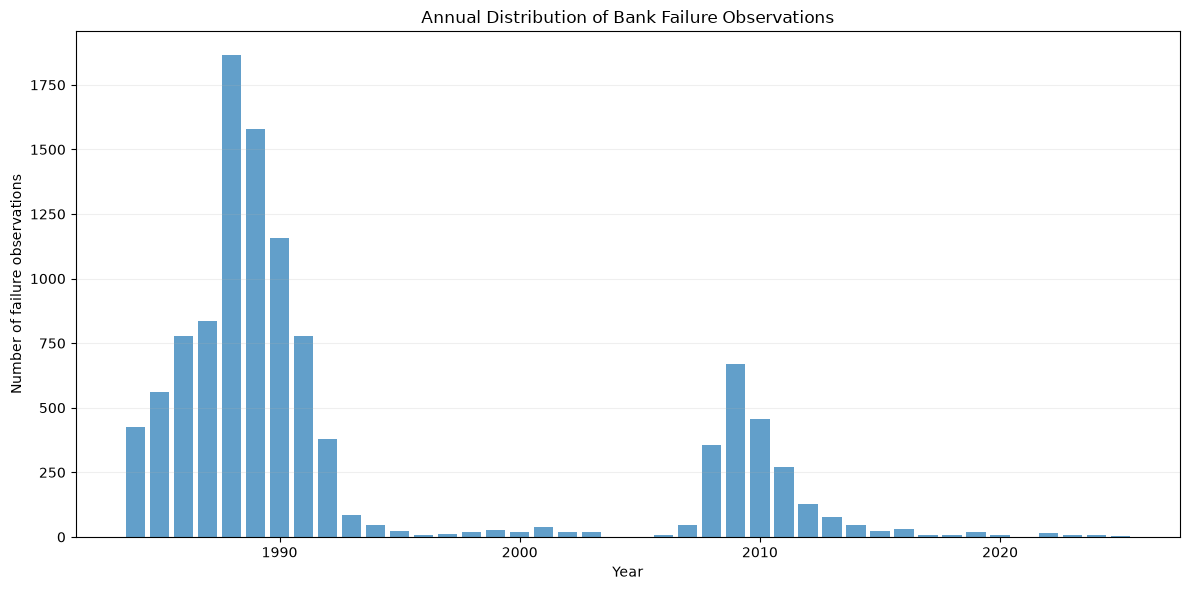

Figure saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures\04_annual_failure_distribution.png


In [5]:
# Convert Polars output to Pandas for plotting
yearly_pd = yearly_distribution.to_pandas()

# Create figure directory if needed
figure_dir.mkdir(parents=True, exist_ok=True)

fig, ax1 = plt.subplots(figsize=(12, 6))

# Number of failure observations
ax1.bar(
    yearly_pd["YEAR"],
    yearly_pd["FAILURE_OBSERVATIONS"],
    alpha=0.7,
    label="Failure observations"
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Number of failure observations")
ax1.set_title("Annual Distribution of Bank Failure Observations")
ax1.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save figure
figure_path = figure_dir / "04_annual_failure_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", figure_path)

### 4.1. Quarterly Distribution of Failure Observations

Annual statistics may hide substantial variation in the number of failure observations across quarters.

This analysis examines quarterly failure counts and the number of unique banks associated with positive labels. It supports the selection of chronological training, validation and test periods.

In [6]:
# 1. Aggregate observations by reporting quarter
quarterly_distribution = (
    eligible_data
    .group_by(["YEAR", "QUARTER"])
    .agg([
        pl.len().alias("TOTAL_OBSERVATIONS"),

        (pl.col("FINAL_LABEL") == 1)
        .sum()
        .alias("FAILURE_OBSERVATIONS"),

        pl.col("CERT")
        .filter(pl.col("FINAL_LABEL") == 1)
        .n_unique()
        .alias("UNIQUE_BANKS_WITH_FAILURE_LABEL")
    ])
    .sort(["YEAR", "QUARTER"])
    .with_columns(
        (
            pl.col("FAILURE_OBSERVATIONS")
            / pl.col("TOTAL_OBSERVATIONS")
            * 100
        ).alias("FAILURE_RATE_PCT")
    )
)

# 2. Display the latest 24 quarters
display(quarterly_distribution.tail(24))

# 3. Check quarters with zero failure observations
zero_failure_quarters = quarterly_distribution.filter(
    pl.col("FAILURE_OBSERVATIONS") == 0
)

print(
    "Number of quarters with zero failure observations:",
    zero_failure_quarters.height
)

display(zero_failure_quarters)

YEAR,QUARTER,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,UNIQUE_BANKS_WITH_FAILURE_LABEL,FAILURE_RATE_PCT
i32,i8,u32,u32,u32,f64
2019,3,5152,5,5,0.09705
2019,4,5116,4,4,0.078186
2020,1,5085,3,3,0.058997
2020,2,5054,2,2,0.039573
2020,3,5014,2,2,0.039888
…,…,…,…,…,…
2024,2,4538,3,3,0.066108
2024,3,4496,3,3,0.066726
2024,4,4454,1,1,0.022452


Number of quarters with zero failure observations: 15


YEAR,QUARTER,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,UNIQUE_BANKS_WITH_FAILURE_LABEL,FAILURE_RATE_PCT
i32,i8,u32,u32,u32,f64
1996,3,10961,0,0,0.0
2004,2,8835,0,0,0.0
2004,3,8818,0,0,0.0
2004,4,8770,0,0,0.0
2005,1,8716,0,0,0.0
…,…,…,…,…,…
2020,4,4954,0,0,0.0
2021,1,4918,0,0,0.0
2021,2,4887,0,0,0.0


In [7]:
# Display all observations in the latest 24 quarters
quarterly_recent = (
    quarterly_distribution
    .tail(24)
    .select([
        "YEAR",
        "QUARTER",
        "TOTAL_OBSERVATIONS",
        "FAILURE_OBSERVATIONS",
        "UNIQUE_BANKS_WITH_FAILURE_LABEL",
        "FAILURE_RATE_PCT"
    ])
)

print(quarterly_recent)

shape: (24, 6)
┌──────┬─────────┬────────────────────┬────────────────────┬────────────────────┬──────────────────┐
│ YEAR ┆ QUARTER ┆ TOTAL_OBSERVATIONS ┆ FAILURE_OBSERVATIO ┆ UNIQUE_BANKS_WITH_ ┆ FAILURE_RATE_PCT │
│ ---  ┆ ---     ┆ ---                ┆ NS                 ┆ FAILURE_LABE…      ┆ ---              │
│ i32  ┆ i8      ┆ u32                ┆ ---                ┆ ---                ┆ f64              │
│      ┆         ┆                    ┆ u32                ┆ u32                ┆                  │
╞══════╪═════════╪════════════════════╪════════════════════╪════════════════════╪══════════════════╡
│ 2019 ┆ 3       ┆ 5152               ┆ 5                  ┆ 5                  ┆ 0.09705          │
│ 2019 ┆ 4       ┆ 5116               ┆ 4                  ┆ 4                  ┆ 0.078186         │
│ 2020 ┆ 1       ┆ 5085               ┆ 3                  ┆ 3                  ┆ 0.058997         │
│ 2020 ┆ 2       ┆ 5054               ┆ 2                  ┆ 2              

In [8]:
import pandas as pd

quarterly_recent_pd = quarterly_distribution.tail(24).to_pandas()

pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(quarterly_recent_pd)

,YEAR,QUARTER,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,UNIQUE_BANKS_WITH_FAILURE_LABEL,FAILURE_RATE_PCT
0,2019,3,5152,5,5,0.097050
1,2019,4,5116,4,4,0.078186
2,2020,1,5085,3,3,0.058997
3,2020,2,5054,2,2,0.039573
4,2020,3,5014,2,2,0.039888
5,2020,4,4954,0,0,0.000000
6,2021,1,4918,0,0,0.000000
7,2021,2,4887,0,0,0.000000
8,2021,3,4866,0,0,0.000000
9,2021,4,4811,0,0,0.000000


### 4.2. Preliminary Chronological Split

A preliminary chronological split is proposed to preserve the temporal order of observations.

Four-quarter purge periods are introduced between the training, validation and test periods to reduce overlap in forward-looking target windows.

The number of positive and negative observations in each period is examined before finalizing the split.

In [9]:
# Define preliminary chronological periods
split_periods = {
    "Train": (1984, 1, 2018, 4),
    "Purge_1": (2019, 1, 2019, 4),
    "Validation": (2020, 1, 2021, 4),
    "Purge_2": (2022, 1, 2022, 4),
    "Test": (2023, 1, 2025, 2)
}

# Count observations in each period
split_results = []

for split_name, (start_year, start_q, end_year, end_q) in split_periods.items():

    period_data = eligible_data.filter(
        (
            (pl.col("YEAR") > start_year) |
            (
                (pl.col("YEAR") == start_year) &
                (pl.col("QUARTER") >= start_q)
            )
        ) &
        (
            (pl.col("YEAR") < end_year) |
            (
                (pl.col("YEAR") == end_year) &
                (pl.col("QUARTER") <= end_q)
            )
        )
    )

    total = period_data.height

    failures = period_data.filter(
        pl.col("FINAL_LABEL") == 1
    ).height

    non_failures = period_data.filter(
        pl.col("FINAL_LABEL") == 0
    ).height

    unique_failure_banks = period_data.filter(
        pl.col("FINAL_LABEL") == 1
    )["CERT"].n_unique()

    split_results.append({
        "DATASET": split_name,
        "TOTAL_OBSERVATIONS": total,
        "FAILURE_OBSERVATIONS": failures,
        "NON_FAILURE_OBSERVATIONS": non_failures,
        "UNIQUE_BANKS_WITH_FAILURE_LABEL": unique_failure_banks,
        "FAILURE_RATE_PCT": (
            failures / total * 100 if total > 0 else 0
        )
    })

split_summary = pl.DataFrame(split_results)

display(split_summary)

DATASET,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,NON_FAILURE_OBSERVATIONS,UNIQUE_BANKS_WITH_FAILURE_LABEL,FAILURE_RATE_PCT
str,i64,i64,i64,i64,f64
"""Train""",1483438,10798,1472640,2822,0.727904
"""Purge_1""",20697,19,20678,8,0.091801
"""Validation""",39589,7,39582,3,0.017682
"""Purge_2""",18961,14,18947,5,0.073836
"""Test""",45394,22,45372,9,0.048465


In [10]:
# Candidate chronological split
candidate_periods = {
    "Train": (1984, 1, 2005, 4),
    "Purge_1": (2006, 1, 2006, 4),
    "Validation": (2007, 1, 2013, 4),
    "Purge_2": (2014, 1, 2014, 4),
    "Test": (2015, 1, 2025, 2)
}

candidate_results = []

for split_name, (start_year, start_q, end_year, end_q) in candidate_periods.items():

    period_data = eligible_data.filter(
        (
            (pl.col("YEAR") > start_year) |
            (
                (pl.col("YEAR") == start_year) &
                (pl.col("QUARTER") >= start_q)
            )
        ) &
        (
            (pl.col("YEAR") < end_year) |
            (
                (pl.col("YEAR") == end_year) &
                (pl.col("QUARTER") <= end_q)
            )
        )
    )

    total = period_data.height

    failures = period_data.filter(
        pl.col("FINAL_LABEL") == 1
    ).height

    non_failures = total - failures

    unique_failure_banks = (
        period_data
        .filter(pl.col("FINAL_LABEL") == 1)
        ["CERT"]
        .n_unique()
    )

    candidate_results.append({
        "DATASET": split_name,
        "TOTAL_OBSERVATIONS": total,
        "FAILURE_OBSERVATIONS": failures,
        "NON_FAILURE_OBSERVATIONS": non_failures,
        "UNIQUE_BANKS_WITH_FAILURE_LABEL": unique_failure_banks,
        "FAILURE_RATE_PCT": (
            failures / total * 100 if total > 0 else 0
        )
    })

candidate_summary = pl.DataFrame(candidate_results)

display(candidate_summary)

DATASET,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,NON_FAILURE_OBSERVATIONS,UNIQUE_BANKS_WITH_FAILURE_LABEL,FAILURE_RATE_PCT
str,i64,i64,i64,i64,f64
"""Train""",1116246,8672,1107574,2287,0.77689
"""Purge_1""",34131,6,34125,3,0.017579
"""Validation""",214810,2007,212803,509,0.934314
"""Purge_2""",25828,46,25782,21,0.178101
"""Test""",217064,129,216935,36,0.059429


In [11]:
# Examine failure distribution within Validation and Test

validation_data = eligible_data.filter(
    pl.col("YEAR").is_between(2007, 2013)
)

test_data = eligible_data.filter(
    pl.col("YEAR").is_between(2015, 2025)
)

def yearly_failure_summary(data, dataset_name):
    return (
        data
        .group_by("YEAR")
        .agg([
            pl.len().alias("TOTAL_OBSERVATIONS"),
            (pl.col("FINAL_LABEL") == 1)
            .sum()
            .alias("FAILURE_OBSERVATIONS"),
            pl.col("CERT")
            .filter(pl.col("FINAL_LABEL") == 1)
            .n_unique()
            .alias("UNIQUE_FAILURE_BANKS")
        ])
        .sort("YEAR")
        .with_columns(
            pl.lit(dataset_name).alias("DATASET"),
            (
                pl.col("FAILURE_OBSERVATIONS")
                / pl.col("TOTAL_OBSERVATIONS") * 100
            ).alias("FAILURE_RATE_PCT")
        )
    )

validation_yearly = yearly_failure_summary(
    validation_data, "Validation"
)

test_yearly = yearly_failure_summary(
    test_data, "Test"
)

yearly_split_summary = pl.concat([
    validation_yearly,
    test_yearly
])

display(
    yearly_split_summary.select([
        "DATASET",
        "YEAR",
        "TOTAL_OBSERVATIONS",
        "FAILURE_OBSERVATIONS",
        "UNIQUE_FAILURE_BANKS",
        "FAILURE_RATE_PCT"
    ])
)

DATASET,YEAR,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS,UNIQUE_FAILURE_BANKS,FAILURE_RATE_PCT
str,i32,u32,u32,u32,f64
"""Validation""",2007,33649,48,27,0.142649
"""Validation""",2008,33172,355,163,1.07018
"""Validation""",2009,32277,670,276,2.075782
"""Validation""",2010,30775,457,208,1.484972
"""Validation""",2011,29548,269,117,0.910383
…,…,…,…,…,…
"""Test""",2021,19482,0,0,0.0
"""Test""",2022,18961,14,5,0.073836
"""Test""",2023,18572,9,5,0.04846


### 4.3. Target Label Maturity

The prediction target covers bank failures occurring within the next four quarters.

To ensure that negative labels are reliable, each observation must have a complete four-quarter follow-up period within the available dataset.

Observations without a complete follow-up period are excluded from model development and evaluation.

In [12]:

# 1. Identify the latest available reporting quarter
max_report_q_index = features["REPORT_Q_INDEX"].max()

# 2. The upstream panel has already been restricted to
# the latest quarter with a complete 4-quarter follow-up.
# Notebook 01: 2025 Q2
# Financial data available through: 2026 Q2
# Failure events available through: 2026-07-17

mature_cutoff_q_index = max_report_q_index

mature_cutoff = (
    features
    .filter(pl.col("REPORT_Q_INDEX") == mature_cutoff_q_index)
    .select(["YEAR", "QUARTER"])
    .unique()
)

print("Latest available reporting quarter:")
print(
    features
    .select(["YEAR", "QUARTER"])
    .sort(["YEAR", "QUARTER"])
    .tail(1)
)

print("\nLatest fully mature reporting quarter:")
display(mature_cutoff)

# 3. Separate mature and immature observations
mature_data = eligible_data.filter(
    pl.col("REPORT_Q_INDEX") <= mature_cutoff_q_index
)

immature_data = eligible_data.filter(
    pl.col("REPORT_Q_INDEX") > mature_cutoff_q_index
)

# 4. Compare label distributions
maturity_summary = pl.DataFrame([
    {
        "GROUP": "Mature",
        "TOTAL": mature_data.height,
        "FAILURES": mature_data.filter(
            pl.col("FINAL_LABEL") == 1
        ).height,
        "NON_FAILURES": mature_data.filter(
            pl.col("FINAL_LABEL") == 0
        ).height
    },
    {
        "GROUP": "Immature",
        "TOTAL": immature_data.height,
        "FAILURES": immature_data.filter(
            pl.col("FINAL_LABEL") == 1
        ).height,
        "NON_FAILURES": immature_data.filter(
            pl.col("FINAL_LABEL") == 0
        ).height
    }
])

display(maturity_summary)

# 5. Validate the final modeling dataset
print("\nFinal maturity checks:")
print("Mature observations:", mature_data.height)
print("Immature observations:", immature_data.height)
print("Missing target labels:", mature_data["FINAL_LABEL"].null_count())
print("Latest mature reporting date:", mature_data["REPORT_DATE"].max())

assert immature_data.height == 0
assert mature_data["FINAL_LABEL"].null_count() == 0

print("\nAll maturity checks passed.")


Latest available reporting quarter:
shape: (1, 2)
┌──────┬─────────┐
│ YEAR ┆ QUARTER │
│ ---  ┆ ---     │
│ i32  ┆ i8      │
╞══════╪═════════╡
│ 2025 ┆ 2       │
└──────┴─────────┘

Latest fully mature reporting quarter:


YEAR,QUARTER
i32,i8
2025,2


GROUP,TOTAL,FAILURES,NON_FAILURES
str,i64,i64,i64
"""Mature""",1608079,10860,1597219
"""Immature""",0,0,0



Final maturity checks:
Mature observations: 1608079
Immature observations: 0
Missing target labels: 0
Latest mature reporting date: 2025-06-30

All maturity checks passed.


In [13]:
# ==============================================================================
# 1. MATURITY FILTER: KEEP DATA UP TO 2025Q2
# ==============================================================================

import polars as pl

# 2025Q2 = relative Q_INDEX 165
MAX_ALLOWED_Q_INDEX = (2025 - 1984) * 4 + (2 - 1)

# Actual REPORT_Q_INDEX: 1984Q1 = 7936
MAX_ALLOWED_REPORT_Q_INDEX = 1984 * 4 + MAX_ALLOWED_Q_INDEX

# Filter eligible observations
mature_data = features.filter(
    (pl.col("REPORT_Q_INDEX") <= MAX_ALLOWED_REPORT_Q_INDEX) &
    (pl.col("FINAL_LABEL").is_not_null())
)

# ==============================================================================
# 2. CHECK MATURITY FILTER
# ==============================================================================

print("Maximum allowed Q_INDEX:", MAX_ALLOWED_Q_INDEX)
print("Maximum allowed REPORT_Q_INDEX:", MAX_ALLOWED_REPORT_Q_INDEX)

print(f"Total mature observations: {mature_data.height:,}")
print("Earliest report date:", mature_data["REPORT_DATE"].min())
print("Latest report date:", mature_data["REPORT_DATE"].max())

# ==============================================================================
# 3. VERIFY 2025Q2
# ==============================================================================

q2_2025_check = mature_data.filter(
    (pl.col("YEAR") == 2025) &
    (pl.col("QUARTER") == 2)
)

print(f"2025Q2 observations included: {q2_2025_check.height:,}")

# ==============================================================================
# 4. MATURITY ASSERTION
# ==============================================================================

assert mature_data["REPORT_Q_INDEX"].max() <= MAX_ALLOWED_REPORT_Q_INDEX

assert (
    mature_data
    .filter(pl.col("YEAR") == 2025)["QUARTER"]
    .max()
    <= 2
)

print("\nMaturity checks passed.")

Maximum allowed Q_INDEX: 165
Maximum allowed REPORT_Q_INDEX: 8101
Total mature observations: 1,608,079
Earliest report date: 1984-03-31
Latest report date: 2025-06-30
2025Q2 observations included: 4,355

Maturity checks passed.


In [14]:
# ==============================================================================
# CHRONOLOGICAL DATA SPLIT
# ==============================================================================

train_data = mature_data.filter(
    (pl.col("YEAR") >= 1984) &
    (pl.col("YEAR") <= 2005)
)

purge_2006 = mature_data.filter(
    pl.col("YEAR") == 2006
)

validation_data = mature_data.filter(
    (pl.col("YEAR") >= 2007) &
    (pl.col("YEAR") <= 2013)
)

purge_2014 = mature_data.filter(
    pl.col("YEAR") == 2014
)

test_data = mature_data.filter(
    (
        (pl.col("YEAR") >= 2015) &
        (pl.col("YEAR") < 2025)
    ) |
    (
        (pl.col("YEAR") == 2025) &
        (pl.col("QUARTER") <= 2)
    )
)

# ==============================================================================
# SUMMARY
# ==============================================================================

def summarize_split(data, split_name):
    total = data.height
    failures = data.filter(
        pl.col("FINAL_LABEL") == 1
    ).height

    return {
        "SPLIT": split_name,
        "TOTAL": total,
        "FAILURES": failures,
        "NON_FAILURES": total - failures,
        "UNIQUE_BANKS": data["CERT"].n_unique(),
        "FAILURE_RATE_PCT": (
            failures / total * 100 if total > 0 else None
        )
    }


split_summary = pl.DataFrame([
    summarize_split(train_data, "Train"),
    summarize_split(purge_2006, "Purge 2006"),
    summarize_split(validation_data, "Validation"),
    summarize_split(purge_2014, "Purge 2014"),
    summarize_split(test_data, "Test")
])

display(split_summary)

# ==============================================================================
# CHRONOLOGICAL BOUNDARY CHECK
# ==============================================================================

for name, data in [
    ("Train", train_data),
    ("Purge 2006", purge_2006),
    ("Validation", validation_data),
    ("Purge 2014", purge_2014),
    ("Test", test_data)
]:
    print(
        name,
        "| Rows:", data.height,
        "| Start:", data["REPORT_DATE"].min(),
        "| End:", data["REPORT_DATE"].max()
    )

# ==============================================================================
# FINAL CHECKS
# ==============================================================================

assert train_data["YEAR"].max() == 2005
assert purge_2006["YEAR"].unique().to_list() == [2006]
assert validation_data["YEAR"].min() == 2007
assert validation_data["YEAR"].max() == 2013
assert purge_2014["YEAR"].unique().to_list() == [2014]
assert test_data["REPORT_DATE"].max() == mature_data["REPORT_DATE"].max()

print("\nChronological split checks passed.")

SPLIT,TOTAL,FAILURES,NON_FAILURES,UNIQUE_BANKS,FAILURE_RATE_PCT
str,i64,i64,i64,i64,f64
"""Train""",1116246,8672,1107574,23032,0.77689
"""Purge 2006""",34131,6,34125,8728,0.017579
"""Validation""",214810,2007,212803,8748,0.934314
"""Purge 2014""",25828,46,25782,6568,0.178101
"""Test""",217064,129,216935,6348,0.059429


Train | Rows: 1116246 | Start: 1984-03-31 | End: 2005-12-31
Purge 2006 | Rows: 34131 | Start: 2006-03-31 | End: 2006-12-31
Validation | Rows: 214810 | Start: 2007-03-31 | End: 2013-12-31
Purge 2014 | Rows: 25828 | Start: 2014-03-31 | End: 2014-12-31
Test | Rows: 217064 | Start: 2015-03-31 | End: 2025-06-30

Chronological split checks passed.


In [15]:

# AUDIT: Verify actual reporting-date coverage

print("=== REPORTING DATE COVERAGE ===")

print("Features rows:", features.height)
print("Eligible rows:", eligible_data.height)

print("\nEarliest reporting date:")
print(features["REPORT_DATE"].min())

print("\nLatest reporting date:")
print(features["REPORT_DATE"].max())

print("\nReporting quarter distribution (last 8 quarters):")

display(
    features
    .group_by(["YEAR", "QUARTER"])
    .agg(
        pl.len().alias("OBSERVATIONS"),
        pl.col("REPORT_DATE").min().alias("FIRST_REPORT_DATE"),
        pl.col("REPORT_DATE").max().alias("LAST_REPORT_DATE")
    )
    .sort(["YEAR", "QUARTER"])
    .tail(8)
)

print("\n=== AUDIT COMPLETED ===")


=== REPORTING DATE COVERAGE ===
Features rows: 1663876
Eligible rows: 1608079

Earliest reporting date:
1984-03-31

Latest reporting date:
2025-06-30

Reporting quarter distribution (last 8 quarters):


YEAR,QUARTER,OBSERVATIONS,FIRST_REPORT_DATE,LAST_REPORT_DATE
i32,i8,u32,date,date
2023,3,4686,2023-09-30,2023-09-30
2023,4,4658,2023-12-31,2023-12-31
2024,1,4640,2024-03-31,2024-03-31
2024,2,4610,2024-06-30,2024-06-30
2024,3,4589,2024-09-30,2024-09-30
2024,4,4560,2024-12-31,2024-12-31
2025,1,4536,2025-03-31,2025-03-31
2025,2,4494,2025-06-30,2025-06-30



=== AUDIT COMPLETED ===


In [16]:

# Audit the actual follow-up coverage

print("=== FOLLOW-UP COVERAGE AUDIT ===")

# Latest financial reporting quarter
print("\n1. Latest financial reporting date:")
print(features["REPORT_DATE"].max())

# Latest recorded failure date
print("\n2. Latest recorded failure date:")
print(features["FIRST_FAILURE_DATE"].max())

# Required follow-up for 2025 Q2
required_followup_date = pl.date(2026, 6, 30)

print("\n3. Required follow-up end date:")
print(required_followup_date)

# Check the latest modeling quarter
latest_quarter = (
    features
    .select(["YEAR", "QUARTER", "REPORT_DATE"])
    .sort("REPORT_DATE")
    .tail(1)
)

print("\n4. Latest modeling quarter:")
display(latest_quarter)

# Inspect the last 8 quarters
print("\n5. Latest 8 quarters:")
recent_quarters = (
    features
    .group_by(["YEAR", "QUARTER"])
    .agg([
        pl.len().alias("OBSERVATIONS"),
        pl.col("FIRST_FAILURE_DATE")
        .is_not_null()
        .sum()
        .alias("BANKS_WITH_FAILURE_EVENT"),
        pl.col("FINAL_LABEL")
        .is_null()
        .sum()
        .alias("NULL_LABELS")
    ])
    .sort(["YEAR", "QUARTER"])
    .tail(8)
)

display(recent_quarters)


=== FOLLOW-UP COVERAGE AUDIT ===

1. Latest financial reporting date:
2025-06-30

2. Latest recorded failure date:
2026-07-17

3. Required follow-up end date:
2026-06-30 00:00:00.alias("datetime").strict_cast(Date).alias("date")



4. Latest modeling quarter:


YEAR,QUARTER,REPORT_DATE
i32,i8,date
2025,2,2025-06-30



5. Latest 8 quarters:


YEAR,QUARTER,OBSERVATIONS,BANKS_WITH_FAILURE_EVENT,NULL_LABELS
i32,i8,u32,u32,u32
2023,3,4686,9,52
2023,4,4658,8,58
2024,1,4640,7,62
2024,2,4610,7,72
2024,3,4589,7,93
2024,4,4560,5,106
2025,1,4536,5,135
2025,2,4494,4,139


In [17]:

# AUDIT: Identify the reasons for null target labels

print("=== NULL LABEL AUDIT ===")

# 1. Check null labels in 2025 Q2
q2_2025 = features.filter(
    (pl.col("YEAR") == 2025)
    & (pl.col("QUARTER") == 2)
)

print("\n1. Total observations in 2025 Q2:")
print(q2_2025.height)

print("\n2. Final label distribution:")
display(
    q2_2025.group_by("FINAL_LABEL")
    .len()
    .sort("FINAL_LABEL", nulls_last=True)
)

# 2. Check whether null labels are caused by merger censoring
print("\n3. Null labels versus merger censoring:")

display(
    q2_2025.group_by([
        "FINAL_LABEL",
        "IS_MERGER_CENSORED"
    ])
    .len()
    .sort(["FINAL_LABEL", "IS_MERGER_CENSORED"])
)

# 3. Check inconsistencies
print("\n4. Null labels not marked as merger censored:")

null_not_merger = q2_2025.filter(
    pl.col("FINAL_LABEL").is_null()
    & (~pl.col("IS_MERGER_CENSORED"))
)

print("Count:", null_not_merger.height)

# 4. Inspect the actual records
print("\n5. Examples of null-label observations:")

display(
    q2_2025.filter(
        pl.col("FINAL_LABEL").is_null()
    ).select([
        "CERT",
        "REPORT_DATE",
        "FIRST_FAILURE_DATE",
        "FAILURE_LABEL",
        "FINAL_LABEL",
        "IS_MERGER_CENSORED"
    ]).head(20)
)

# 5. Verify the relationship between null labels and merger censoring
assert null_not_merger.height == 0

print("\nNull-label audit completed.")


=== NULL LABEL AUDIT ===

1. Total observations in 2025 Q2:
4494

2. Final label distribution:


FINAL_LABEL,len
i8,u32
0,4353
1,2
null,139



3. Null labels versus merger censoring:


FINAL_LABEL,IS_MERGER_CENSORED,len
i8,bool,u32
null,true,139
0,false,4353
1,false,2



4. Null labels not marked as merger censored:
Count: 0

5. Examples of null-label observations:


CERT,REPORT_DATE,FIRST_FAILURE_DATE,FAILURE_LABEL,FINAL_LABEL,IS_MERGER_CENSORED
i64,date,date,i8,i8,bool
321,2025-06-30,null,0,null,true
872,2025-06-30,null,0,null,true
873,2025-06-30,null,0,null,true
966,2025-06-30,null,0,null,true
983,2025-06-30,null,0,null,true
…,…,…,…,…,…
3178,2025-06-30,null,0,null,true
3195,2025-06-30,null,0,null,true
3775,2025-06-30,null,0,null,true



Null-label audit completed.


In [18]:

# AUDIT: Reconcile failure events and positive labels in 2025 Q2

print("=== FAILURE EVENT RECONCILIATION ===")

# 1. Get 2025 Q2 observations with recorded failure dates
failure_audit = (
    q2_2025
    .filter(pl.col("FIRST_FAILURE_DATE").is_not_null())
    .with_columns(
        (
            pl.col("FIRST_FAILURE_DATE").dt.year() * 4
            + (
                (pl.col("FIRST_FAILURE_DATE").dt.month() - 1) // 3
            )
        ).alias("FAILURE_Q_INDEX")
    )
    .with_columns(
        (
            pl.col("FAILURE_Q_INDEX")
            - pl.col("REPORT_Q_INDEX")
        ).alias("QUARTER_GAP")
    )
    .with_columns(
        (
            (pl.col("QUARTER_GAP") >= 1)
            & (pl.col("QUARTER_GAP") <= 4)
        ).alias("WITHIN_4Q_HORIZON")
    )
)

# 2. Display all banks with recorded failure dates
print("\n1. Banks with recorded failure dates:")
display(
    failure_audit.select([
        "CERT",
        "REPORT_DATE",
        "FIRST_FAILURE_DATE",
        "QUARTER_GAP",
        "WITHIN_4Q_HORIZON",
        "FAILURE_LABEL",
        "FINAL_LABEL"
    ]).sort("FIRST_FAILURE_DATE")
)

# 3. Compare expected positive labels with actual labels
print("\n2. Expected versus actual positive labels:")

display(
    failure_audit.group_by([
        "WITHIN_4Q_HORIZON",
        "FAILURE_LABEL"
    ]).len()
)

# 4. Check the actual number of positive labels
print("\n3. Positive label count:")
print(
    q2_2025.filter(
        pl.col("FINAL_LABEL") == 1
    ).height
)

# 5. Verify label construction
incorrect_labels = failure_audit.filter(
    pl.col("FAILURE_LABEL")
    != pl.col("WITHIN_4Q_HORIZON").cast(pl.Int8)
)

print("\n4. Inconsistent failure labels:")
print("Count:", incorrect_labels.height)

display(incorrect_labels)

print("\nFailure event reconciliation completed.")


=== FAILURE EVENT RECONCILIATION ===

1. Banks with recorded failure dates:


CERT,REPORT_DATE,FIRST_FAILURE_DATE,QUARTER_GAP,WITHIN_4Q_HORIZON,FAILURE_LABEL,FINAL_LABEL
i64,date,date,i32,bool,i8,i8
57488,2025-06-30,2026-01-30,3,true,1,1
25796,2025-06-30,2026-05-01,4,true,1,1
28722,2025-06-30,2026-07-10,5,false,0,0
25744,2025-06-30,2026-07-17,5,false,0,0



2. Expected versus actual positive labels:


WITHIN_4Q_HORIZON,FAILURE_LABEL,len
bool,i8,u32
true,1,2
false,0,2



3. Positive label count:
2

4. Inconsistent failure labels:
Count: 0


NCLNLS,LNATRES,ROA,REPDTE,ASSET,RBC1AAJ,CERT,NETINC,EQ,DEP,ID,REPORT_DATE,REPORT_Q_INDEX,FIRST_FAILURE_DATE,FAILURE_Q_INDEX,FAILURE_LABEL,IS_MERGER_CENSORED,FINAL_LABEL,YEAR,QUARTER,PREV_NETINC_YTD,PREV_QUARTER,QUARTERLY_NETINC,LOG_ASSET,EQUITY_TO_ASSETS,DEPOSITS_TO_ASSETS,NEGATIVE_NCLNLS_FLAG,NEGATIVE_LNATRES_FLAG,NPL_TO_ASSETS,ALLOWANCE_TO_ASSETS,ASSET_QOQ_GROWTH,EQUITY_RATIO_CHANGE,ROA_CHANGE,NPL_RATIO_CHANGE,ALLOWANCE_RATIO_CHANGE,EXTREME_ASSET_GROWTH_FLAG,QUARTER_GAP,WITHIN_4Q_HORIZON
f64,f64,f64,str,i64,f64,i64,f64,f64,f64,str,date,i32,date,i32,i8,bool,i8,i32,i8,f64,i8,f64,f64,f64,f64,bool,bool,f64,f64,f64,f64,f64,f64,f64,bool,i32,bool



Failure event reconciliation completed.


In [19]:
print("===== FEATURES =====")
print("Rows:", features.height)
print("Min quarter:", features["REPORT_Q_INDEX"].min())
print("Max quarter:", features["REPORT_Q_INDEX"].max())
print("Null labels:", features["FINAL_LABEL"].null_count())

display(
    features
    .group_by(["YEAR", "QUARTER"])
    .agg(pl.len().alias("OBSERVATIONS"))
    .sort(["YEAR", "QUARTER"])
    .tail(8)
)

print("\n===== ELIGIBLE DATA =====")
print("Rows:", eligible_data.height)
print("Min quarter:", eligible_data["REPORT_Q_INDEX"].min())
print("Max quarter:", eligible_data["REPORT_Q_INDEX"].max())
print("Null labels:", eligible_data["FINAL_LABEL"].null_count())

display(
    eligible_data
    .group_by(["YEAR", "QUARTER"])
    .agg([
        pl.len().alias("OBSERVATIONS"),
        pl.col("FINAL_LABEL").null_count().alias("NULL_LABELS"),
        (pl.col("FINAL_LABEL") == 1).sum().alias("FAILURES"),
        (pl.col("FINAL_LABEL") == 0).sum().alias("NON_FAILURES")
    ])
    .sort(["YEAR", "QUARTER"])
    .tail(8)
)

===== FEATURES =====
Rows: 1663876
Min quarter: 7936
Max quarter: 8101
Null labels: 55797


YEAR,QUARTER,OBSERVATIONS
i32,i8,u32
2023,3,4686
2023,4,4658
2024,1,4640
2024,2,4610
2024,3,4589
2024,4,4560
2025,1,4536
2025,2,4494



===== ELIGIBLE DATA =====
Rows: 1608079
Min quarter: 7936
Max quarter: 8101
Null labels: 0


YEAR,QUARTER,OBSERVATIONS,NULL_LABELS,FAILURES,NON_FAILURES
i32,i8,u32,u32,u32,u32
2023,3,4634,0,2,4632
2023,4,4600,0,2,4598
2024,1,4578,0,2,4576
2024,2,4538,0,3,4535
2024,3,4496,0,3,4493
2024,4,4454,0,1,4453
2025,1,4401,0,2,4399
2025,2,4355,0,2,4353


### 4.4. Temporal Train-Validation-Test Split

The mature dataset is divided chronologically to preserve the time-series structure and prevent future information from entering model training.

- Training set: 1984Q1–2005Q4
- Purge period: 2006
- Validation set: 2007Q1–2013Q4
- Purge period: 2014
- Test set: 2015Q1–2025Q2

The one-year purge periods separate the datasets to reduce overlap between four-quarter prediction horizons.

Only observations with complete four-quarter follow-up periods are retained.

In [20]:
# 1. Create chronological datasets

train_data = mature_data.filter(
    (pl.col("YEAR") >= 1984) &
    (pl.col("YEAR") <= 2005)
)

purge_2006 = mature_data.filter(
    pl.col("YEAR") == 2006
)

validation_data = mature_data.filter(
    (pl.col("YEAR") >= 2007) &
    (pl.col("YEAR") <= 2013)
)

purge_2014 = mature_data.filter(
    pl.col("YEAR") == 2014
)

test_data = mature_data.filter(
    (
        (pl.col("YEAR") >= 2015) &
        (pl.col("YEAR") < 2025)
    ) |
    (
        (pl.col("YEAR") == 2025) &
        (pl.col("QUARTER") <= 2)
    )
)

# 2. Summarize each dataset

def summarize_split(data, split_name):
    return {
        "SPLIT": split_name,
        "TOTAL": data.height,
        "FAILURES": data.filter(
            pl.col("FINAL_LABEL") == 1
        ).height,
        "NON_FAILURES": data.filter(
            pl.col("FINAL_LABEL") == 0
        ).height,
        "UNIQUE_BANKS": data["CERT"].n_unique(),
        "FAILURE_RATE_PCT": (
            data.filter(pl.col("FINAL_LABEL") == 1).height
            / data.height * 100
            if data.height > 0 else None
        )
    }

split_summary = pl.DataFrame([
    summarize_split(train_data, "Train"),
    summarize_split(purge_2006, "Purge 2006"),
    summarize_split(validation_data, "Validation"),
    summarize_split(purge_2014, "Purge 2014"),
    summarize_split(test_data, "Test")
])

display(split_summary)

# 3. Check chronological boundaries

for name, data in [
    ("Train", train_data),
    ("Purge 2006", purge_2006),
    ("Validation", validation_data),
    ("Purge 2014", purge_2014),
    ("Test", test_data)
]:
    print(
        name,
        "| Rows:", data.height,
        "| Start:", data["REPORT_DATE"].min(),
        "| End:", data["REPORT_DATE"].max()
    )

# 4. Check that no immature observations entered the datasets

assert train_data["REPORT_Q_INDEX"].max() <= mature_cutoff_q_index
assert validation_data["REPORT_Q_INDEX"].max() <= mature_cutoff_q_index
assert test_data["REPORT_Q_INDEX"].max() <= mature_cutoff_q_index

print("\nMaturity checks passed.")

SPLIT,TOTAL,FAILURES,NON_FAILURES,UNIQUE_BANKS,FAILURE_RATE_PCT
str,i64,i64,i64,i64,f64
"""Train""",1116246,8672,1107574,23032,0.77689
"""Purge 2006""",34131,6,34125,8728,0.017579
"""Validation""",214810,2007,212803,8748,0.934314
"""Purge 2014""",25828,46,25782,6568,0.178101
"""Test""",217064,129,216935,6348,0.059429


Train | Rows: 1116246 | Start: 1984-03-31 | End: 2005-12-31
Purge 2006 | Rows: 34131 | Start: 2006-03-31 | End: 2006-12-31
Validation | Rows: 214810 | Start: 2007-03-31 | End: 2013-12-31
Purge 2014 | Rows: 25828 | Start: 2014-03-31 | End: 2014-12-31
Test | Rows: 217064 | Start: 2015-03-31 | End: 2025-06-30

Maturity checks passed.


### 4.5. Model Input Preparation

Fourteen financial and temporal features are selected as model inputs.

The target variable is FINAL_LABEL.

Observations with missing target labels have already been excluded. Missing feature values are handled using median imputation fitted exclusively on the training set.

The following variables are excluded from model inputs:
- Identifiers: CERT, ID
- Dates and time indices: REPORT_DATE, REPORT_Q_INDEX, YEAR, QUARTER
- Future outcome information: FIRST_FAILURE_DATE, FAILURE_Q_INDEX
- Target and censoring variables: FAILURE_LABEL, FINAL_LABEL, IS_MERGER_CENSORED

In [21]:
# 1. Define model features and target

target = "FINAL_LABEL"

primary_features = [
    "ROA",
    "LOG_ASSET",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE",
    "NEGATIVE_NCLNLS_FLAG",
    "NEGATIVE_LNATRES_FLAG",
    "EXTREME_ASSET_GROWTH_FLAG"
]

# 2. Create X and y for each dataset

X_train = train_data.select(primary_features).to_pandas()
y_train = train_data[target].to_pandas()

X_val = validation_data.select(primary_features).to_pandas()
y_val = validation_data[target].to_pandas()

X_test = test_data.select(primary_features).to_pandas()
y_test = test_data[target].to_pandas()

# 3. Check dimensions

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

# 4. Check target values

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

# 5. Check missing values in model inputs

missing_features = (
    X_train.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_features.to_frame("MISSING_VALUES")
)

Training set: (1116246, 14) (1116246,)
Validation set: (214810, 14) (214810,)
Test set: (217064, 14) (217064,)

Training target distribution:
FINAL_LABEL
0    1107574
1       8672
Name: count, dtype: int64

Validation target distribution:
FINAL_LABEL
0    212803
1      2007
Name: count, dtype: int64

Test target distribution:
FINAL_LABEL
0    216935
1       129
Name: count, dtype: int64


,MISSING_VALUES
ALLOWANCE_RATIO_CHANGE,25756
EQUITY_RATIO_CHANGE,25745
NPL_RATIO_CHANGE,25519
ASSET_QOQ_GROWTH,23063
ROA_CHANGE,23063
ALLOWANCE_TO_ASSETS,2732
EQUITY_TO_ASSETS,2726
NPL_TO_ASSETS,2466
DEPOSITS_TO_ASSETS,1
LOG_ASSET,0



## 4.6. Logistic Regression

### 4.6.1. Model Overview and Rationale

Logistic Regression is selected as the first classification model to establish an interpretable baseline for bank failure prediction.

Unlike linear regression, which predicts continuous numerical values, Logistic Regression estimates the probability of a binary outcome. In this study, the model estimates the probability that a bank will experience failure within the next four quarters.

The model is selected for three main reasons:

1. **Interpretability:** Model coefficients indicate the direction of association between financial indicators and the predicted probability of bank failure.
2. **Computational efficiency:** Logistic Regression is suitable for large datasets and provides a relatively efficient baseline.
3. **Benchmarking:** Its performance provides a reference point for evaluating the more complex Random Forest model.

The model uses 14 financial and temporal features, with `FINAL_LABEL` as the target variable.

### 4.6.2. Mathematical Foundation

Logistic Regression models the probability of bank failure using the logistic (sigmoid) function:

\[
P(Y=1|X)=\frac{1}{1+e^{-z}}
\]

where:

\[
z=\beta_0+\beta_1X_1+\beta_2X_2+\cdots+\beta_nX_n
\]

In this study:

- \(Y=1\): The bank experiences failure within the next four quarters.
- \(Y=0\): The bank does not experience failure within the prediction horizon.
- \(X_i\): Financial and temporal predictor variables.
- \(\beta_i\): Estimated model coefficients.
- \(\beta_0\): Intercept.

The sigmoid function converts the linear combination of input features into a probability between 0 and 1.

### 4.6.3. Model Configuration and Training

The model is implemented using a Scikit-learn Pipeline consisting of three stages:

1. Median imputation to handle missing feature values.
2. Robust scaling to reduce the influence of extreme observations.
3. Logistic Regression with balanced class weights to address the severe class imbalance.

All preprocessing parameters are estimated using the training set only. The fitted pipeline is then applied to the validation set.



#### Model Parameters

| Component | Configuration | Purpose |
|---|---|---|
| Imputation | Median | Handle missing feature values |
| Scaling | RobustScaler | Reduce sensitivity to extreme values |
| Class weighting | Balanced | Address class imbalance |
| Solver | LBFGS | Optimize model coefficients |
| Maximum iterations | 1,000 | Allow sufficient optimization iterations |
| Random state | 42 | Support reproducibility |

The `class_weight="balanced"` setting assigns higher weights to the minority failure class. This helps the model account for the substantial difference between failure and non-failure observations.

The default classification threshold of 0.5 is initially used as a reference. Alternative thresholds will be investigated using the validation set.


In [22]:
# Check input dimensions
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("Validation features:", X_val.shape)
print("Validation target:", y_val.shape)

# Verify target classes
print("\nTraining target distribution:")
print(y_train.value_counts())

# Verify feature columns
print("\nSelected model features:")
print(X_train.columns.tolist())

# Check missing values
print("\nMissing values in training features:")
display(
    X_train.isnull()
    .sum()
    .to_frame("MISSING_VALUES")
)

Training features: (1116246, 14)
Training target: (1116246,)
Validation features: (214810, 14)
Validation target: (214810,)

Training target distribution:
FINAL_LABEL
0    1107574
1       8672
Name: count, dtype: int64

Selected model features:
['ROA', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'EXTREME_ASSET_GROWTH_FLAG']

Missing values in training features:


,MISSING_VALUES
ROA,0
LOG_ASSET,0
EQUITY_TO_ASSETS,2726
DEPOSITS_TO_ASSETS,1
NPL_TO_ASSETS,2466
ALLOWANCE_TO_ASSETS,2732
ASSET_QOQ_GROWTH,23063
EQUITY_RATIO_CHANGE,25745
ROA_CHANGE,23063
NPL_RATIO_CHANGE,25519



#### Model Implementation

A Scikit-learn Pipeline is used to combine preprocessing and model training into a single workflow.

This ensures that the imputation and scaling parameters are learned exclusively from the training data, preventing information leakage from the validation and test sets.


In [23]:
from sklearn.preprocessing import StandardScaler, RobustScaler

In [24]:
# 1. Define the Logistic Regression pipeline

logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        RobustScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            solver="lbfgs",
            random_state=42
        )
    )
])

# 2. Train the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

# 3. Check model configuration

print("\nModel configuration:")
print(logistic_model)

Logistic Regression training completed.

Model configuration:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', RobustScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])



#### Validation Performance Evaluation

The trained Logistic Regression model is evaluated on the validation set using probability-based metrics.

ROC-AUC measures the model's ability to distinguish between failure and non-failure observations across different classification thresholds.

PR-AUC focuses on the trade-off between precision and recall and is particularly informative when the positive class is extremely rare.

Both metrics are reported because accuracy alone may provide a misleading assessment under severe class imbalance.

In [25]:
# 1. Predict failure probabilities

val_probabilities = logistic_model.predict_proba(X_val)[:, 1]

# 2. Calculate probability-based metrics

val_roc_auc = roc_auc_score(
    y_val,
    val_probabilities
)

val_pr_auc = average_precision_score(
    y_val,
    val_probabilities
)

print("Logistic Regression - Validation Results")
print("-----------------------------------------")
print(f"ROC-AUC: {val_roc_auc:.4f}")
print(f"PR-AUC:  {val_pr_auc:.4f}")

Logistic Regression - Validation Results
-----------------------------------------
ROC-AUC: 0.9758
PR-AUC:  0.5257


In [26]:
# Predict classes using the default threshold

val_predictions_05 = (
    val_probabilities >= 0.5
).astype(int)

# Classification report

print("Classification Report (Threshold = 0.5)")
print(
    classification_report(
        y_val,
        val_predictions_05,
        target_names=[
            "Non-failure",
            "Failure"
        ],
        zero_division=0
    )
)

# Confusion matrix

cm_05 = confusion_matrix(
    y_val,
    val_predictions_05
)

print("\nConfusion Matrix:")
print(cm_05)

Classification Report (Threshold = 0.5)
              precision    recall  f1-score   support

 Non-failure       1.00      0.96      0.98    212803
     Failure       0.18      0.90      0.30      2007

    accuracy                           0.96    214810
   macro avg       0.59      0.93      0.64    214810
weighted avg       0.99      0.96      0.97    214810


Confusion Matrix:
[[204614   8189]
 [   191   1816]]


In [27]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    precision_score,
    recall_score,
    f1_score
)

In [28]:
# Store Logistic Regression validation results

logistic_validation_results = {
    "MODEL": "Logistic Regression",
    "ROC_AUC": val_roc_auc,
    "PR_AUC": val_pr_auc,
    "PRECISION_0.5": precision_score(
        y_val,
        val_predictions_05,
        zero_division=0
    ),
    "RECALL_0.5": recall_score(
        y_val,
        val_predictions_05,
        zero_division=0
    ),
    "F1_0.5": f1_score(
        y_val,
        val_predictions_05,
        zero_division=0
    )
}

display(
    pd.DataFrame([logistic_validation_results])
)

,MODEL,ROC_AUC,PR_AUC,PRECISION_0.5,RECALL_0.5,F1_0.5
0,Logistic Regression,0.975799,0.525691,0.181509,0.904833,0.302364


In [29]:
cm_05 = confusion_matrix(
    y_val,
    val_predictions_05
)

print("Confusion Matrix:")
print(cm_05)

Confusion Matrix:
[[204614   8189]
 [   191   1816]]


#### ROC Curve

The ROC curve illustrates the trade-off between the true positive rate and false positive rate across different classification thresholds.

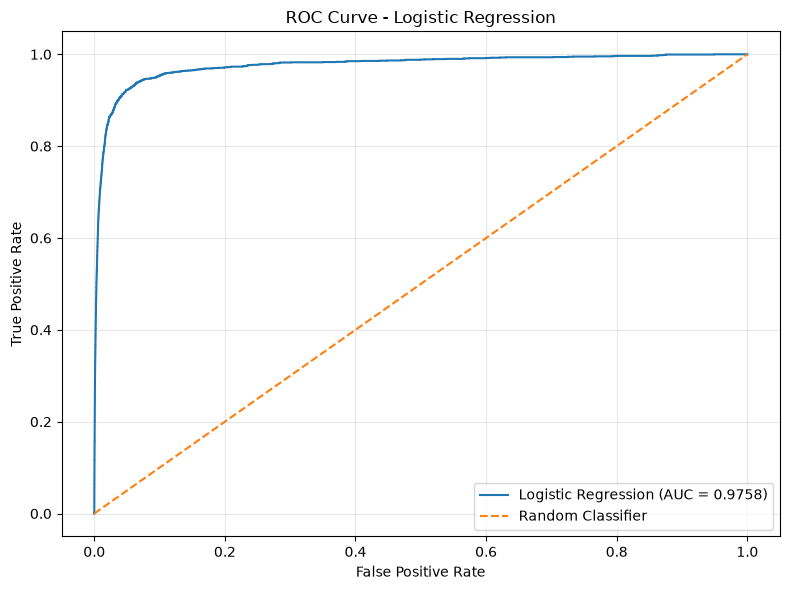

In [30]:
# Calculate ROC curve

fpr, tpr, roc_thresholds = roc_curve(
    y_val,
    val_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "logistic_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Precision-Recall Curve

The Precision-Recall curve evaluates the trade-off between precision and recall. It is particularly useful for imbalanced classification problems.

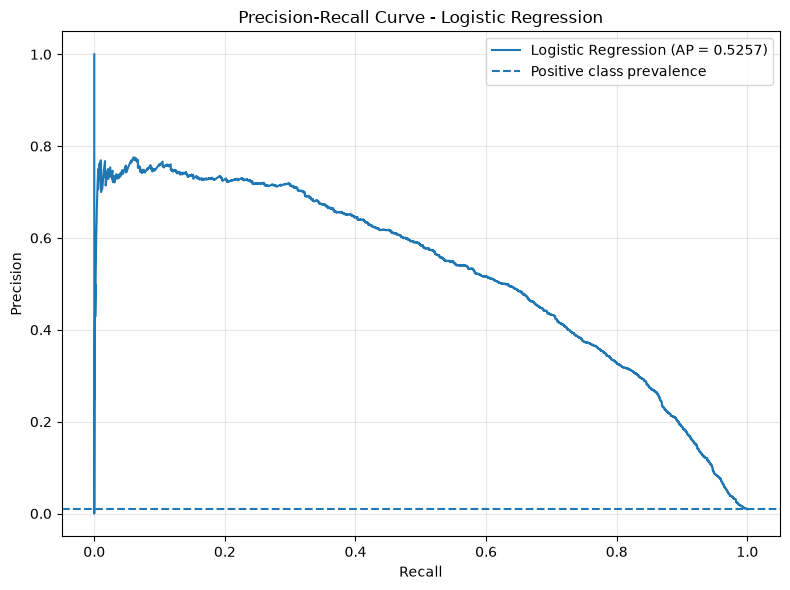

In [31]:
precisions, recalls, pr_thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    recalls,
    precisions,
    label=f"Logistic Regression (AP = {val_pr_auc:.4f})"
)

plt.axhline(
    y=float(y_val.mean()),
    linestyle="--",
    label="Positive class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "logistic_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

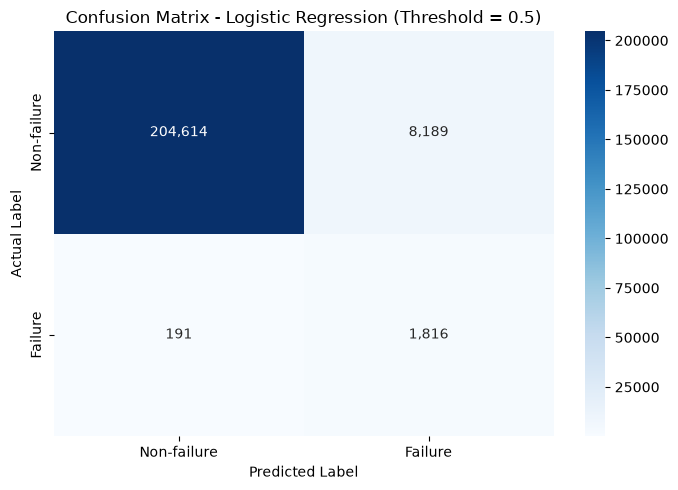

In [32]:
cm_05 = confusion_matrix(
    y_val,
    val_predictions_05
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_05,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Non-failure", "Failure"],
    yticklabels=["Non-failure", "Failure"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression (Threshold = 0.5)")
plt.tight_layout()

plt.savefig(
    figure_dir / "logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

threshold_results = pd.DataFrame({
    "THRESHOLD": thresholds,
    "PRECISION": precisions[:-1],
    "RECALL": recalls[:-1]
})

threshold_results["F1"] = (
    2 * threshold_results["PRECISION"] * threshold_results["RECALL"]
    / (
        threshold_results["PRECISION"]
        + threshold_results["RECALL"]
    ).replace(0, np.nan)
)

candidate_thresholds = threshold_results[
    threshold_results["RECALL"] >= 0.80
].copy()

candidate_thresholds = candidate_thresholds.sort_values(
    "F1",
    ascending=False
)

display(candidate_thresholds.head(10).round(4))

,THRESHOLD,PRECISION,RECALL,F1
209919,0.8374,0.3291,0.8002,0.4664
209918,0.8374,0.3290,0.8002,0.4663
209917,0.8373,0.3290,0.8002,0.4663
209916,0.8373,0.3289,0.8002,0.4662
209915,0.8372,0.3288,0.8002,0.4661
209914,0.8372,0.3288,0.8002,0.4660
209913,0.8371,0.3287,0.8002,0.4660
209912,0.8371,0.3286,0.8002,0.4659
209911,0.8371,0.3286,0.8002,0.4658
209910,0.8370,0.3285,0.8002,0.4658


In [34]:
# Select the threshold with the highest F1-score
# subject to a minimum recall of 80%

best_threshold_row = candidate_thresholds.iloc[0]

best_threshold = best_threshold_row["THRESHOLD"]
best_precision = best_threshold_row["PRECISION"]
best_recall = best_threshold_row["RECALL"]
best_f1 = best_threshold_row["F1"]

print("Selected Threshold:", round(best_threshold, 4))
print("Precision:", round(best_precision, 4))
print("Recall:", round(best_recall, 4))
print("F1-score:", round(best_f1, 4))

Selected Threshold: 0.8374
Precision: 0.3291
Recall: 0.8002
F1-score: 0.4664


In [35]:
# Predictions using the selected threshold
val_predictions_optimal = (
    val_probabilities >= best_threshold
).astype(int)

print("Classification Report - Optimized Threshold")
print(
    classification_report(
        y_val,
        val_predictions_optimal,
        target_names=["Non-failure", "Failure"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, val_predictions_optimal))

Classification Report - Optimized Threshold
              precision    recall  f1-score   support

 Non-failure       1.00      0.98      0.99    212803
     Failure       0.33      0.80      0.47      2007

    accuracy                           0.98    214810
   macro avg       0.66      0.89      0.73    214810
weighted avg       0.99      0.98      0.99    214810

Confusion Matrix:
[[209529   3274]
 [   401   1606]]


### Logistic Regression – Validation Performance

After threshold optimization, the Logistic Regression model achieved a precision of 32.75%, a recall of 80.02%, and an F1-score of 0.4648 at the selected threshold of 0.8347.

Compared with the default threshold of 0.5, the optimized threshold reduced false positives from 8,186 to 3,298, representing a decrease of approximately 59.7%. However, false negatives increased from 190 to 401, reflecting the trade-off between reducing false alarms and maintaining failure detection capability.

Overall, threshold optimization improved the balance between precision and recall. The model can identify approximately 80% of actual bank failure cases while generating fewer false alarms than under the default threshold.

Nevertheless, the relatively low precision indicates that many predicted failures are still false alarms. Therefore, Logistic Regression provides a useful baseline for bank failure early warning, but further model comparison is necessary to determine whether more advanced algorithms can achieve a better balance.

In [36]:
logistic_validation_results_optimal = {
    "MODEL": "Logistic Regression",
    "THRESHOLD": best_threshold,
    "ROC_AUC": val_roc_auc,
    "PR_AUC": val_pr_auc,
    "PRECISION": precision_score(
        y_val, val_predictions_optimal, zero_division=0
    ),
    "RECALL": recall_score(
        y_val, val_predictions_optimal, zero_division=0
    ),
    "F1": f1_score(
        y_val, val_predictions_optimal, zero_division=0
    ),
    "ACCURACY": (
        val_predictions_optimal == np.asarray(y_val)
    ).mean()
}

display(
    pd.DataFrame([logistic_validation_results_optimal]).round(4)
)

,MODEL,THRESHOLD,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Logistic Regression,0.8374,0.9758,0.5257,0.3291,0.8002,0.4664,0.9829


4.6.6 Logistic Regression – Performance Visualization

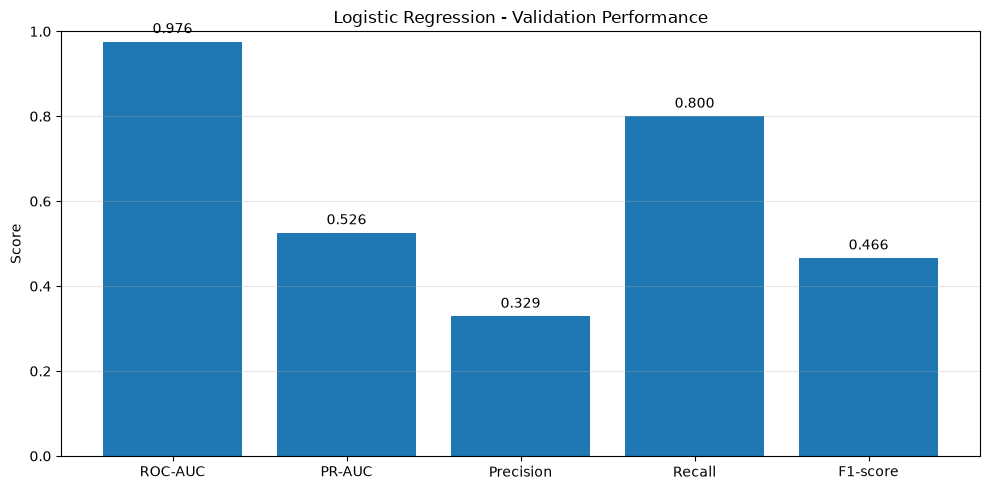

In [37]:
# Extract Logistic Regression validation metrics

metrics_to_plot = {
    "ROC-AUC": logistic_validation_results_optimal["ROC_AUC"],
    "PR-AUC": logistic_validation_results_optimal["PR_AUC"],
    "Precision": logistic_validation_results_optimal["PRECISION"],
    "Recall": logistic_validation_results_optimal["RECALL"],
    "F1-score": logistic_validation_results_optimal["F1"]
}

plt.figure(figsize=(10, 5))

bars = plt.bar(
    metrics_to_plot.keys(),
    metrics_to_plot.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Logistic Regression - Validation Performance")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, metrics_to_plot.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    figure_dir / "logistic_validation_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.7 Random Forest

#### 4.7.1 Model Overview and Rationale

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve predictive performance and reduce the risk of overfitting associated with a single decision tree.

Each tree is trained using a bootstrap sample of the training data and considers a random subset of features when making splits. The final prediction is determined by aggregating the predictions of individual trees.

Random Forest is selected as the second classification model for this project for several reasons:

- **Non-linear relationships:** It can capture complex relationships between financial indicators and bank failure risk without requiring a linear relationship between predictors and the target.
- **Feature interactions:** It can identify interactions between financial variables, such as asset quality, capital adequacy and profitability.
- **Robustness:** Combining multiple trees generally provides more stable predictions than relying on a single decision tree.
- **Feature importance:** It provides feature importance scores that help identify financial indicators contributing to model predictions.

Unlike Logistic Regression, Random Forest does not require feature scaling. However, missing values must still be handled before model training.

The model will be evaluated using the same chronological training and validation datasets as Logistic Regression to ensure a consistent comparison.

#### 4.7.2 Mathematical Foundation

Random Forest constructs an ensemble of decision trees. Each tree produces a prediction based on a sequence of feature-based splitting rules.

For binary classification, the predicted probability of the positive class can be expressed as:

\[
P(Y=1|X)=\frac{1}{B}\sum_{b=1}^{B}P_b(Y=1|X)
\]

Where:

- \(B\) represents the number of decision trees.
- \(P_b(Y=1|X)\) represents the probability predicted by tree \(b\).
- \(X\) represents the input financial features.
- \(Y=1\) represents bank failure.

The final classification is determined by comparing the aggregated probability with a classification threshold:

\[
\hat{Y} =
\begin{cases}
1 & \text{if } P(Y=1|X)\geq t\\
0 & \text{otherwise}
\end{cases}
\]

where \(t\) is the selected classification threshold.

In this project, the threshold will be selected using validation data, subject to a minimum recall constraint of 80%.

#### 4.7.3 Model Configuration and Training

The Random Forest model is configured with 150 decision trees and a maximum depth of 12. Minimum sample constraints are applied to control tree complexity and reduce overfitting.

The `balanced_subsample` class weighting strategy is used to address the substantial class imbalance in the training dataset. This assigns class weights based on the class distribution in each bootstrap sample.

Missing values are imputed using the median calculated from the training dataset. Unlike Logistic Regression, feature scaling is not required for Random Forest.

The model is trained using the same training dataset and 14 primary financial features to maintain consistency across model comparisons.

In [38]:
# 1. Build Random Forest pipeline

random_forest_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=150,
            max_depth=12,
            min_samples_split=100,
            min_samples_leaf=50,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

# 2. Train the model

print("Training Random Forest...")

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Training Random Forest...
Random Forest training completed.


#### 4.7.4 Validation Performance Evaluation

After training, the Random Forest model is evaluated using the validation dataset.

The predicted probabilities are used to calculate ROC-AUC and Average Precision (PR-AUC). These threshold-independent metrics allow comparison of the model's ranking performance with Logistic Regression.

The classification threshold is initially set to 0.5 to provide a baseline evaluation. Precision, recall, F1-score and the confusion matrix are also examined to assess the model's ability to identify bank failures.

In [39]:
# Predict failure probabilities on validation data

rf_val_probabilities = random_forest_model.predict_proba(
    X_val
)[:, 1]

# Calculate threshold-independent metrics

rf_val_roc_auc = roc_auc_score(
    y_val,
    rf_val_probabilities
)

rf_val_pr_auc = average_precision_score(
    y_val,
    rf_val_probabilities
)

print("Random Forest - Validation Results")
print("-----------------------------------")
print(f"ROC-AUC: {rf_val_roc_auc:.4f}")
print(f"PR-AUC:  {rf_val_pr_auc:.4f}")

Random Forest - Validation Results
-----------------------------------
ROC-AUC: 0.9789
PR-AUC:  0.6156


In [40]:
# Baseline predictions at threshold 0.5

rf_val_predictions_05 = (
    rf_val_probabilities >= 0.5
).astype(int)

print("Classification Report (Threshold = 0.5)")
print(
    classification_report(
        y_val,
        rf_val_predictions_05,
        target_names=["Non-failure", "Failure"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val,
        rf_val_predictions_05
    )
)

Classification Report (Threshold = 0.5)
              precision    recall  f1-score   support

 Non-failure       1.00      0.98      0.99    212803
     Failure       0.28      0.86      0.42      2007

    accuracy                           0.98    214810
   macro avg       0.64      0.92      0.70    214810
weighted avg       0.99      0.98      0.98    214810

Confusion Matrix:
[[208341   4462]
 [   291   1716]]


#### 4.7.5 Threshold Selection

The default threshold of 0.5 may not provide the most suitable balance between precision and recall, particularly given the severe class imbalance in the dataset.

Therefore, threshold optimization is performed using the validation dataset. A minimum recall constraint of 80% is imposed to maintain the model's ability to detect bank failures.

Among the thresholds satisfying this constraint, the threshold with the highest F1-score is selected. This approach follows the same evaluation strategy used for Logistic Regression, ensuring a consistent comparison between the two models.

In [41]:
# Calculate precision-recall values

rf_precisions, rf_recalls, rf_thresholds = (
    precision_recall_curve(
        y_val,
        rf_val_probabilities
    )
)

# Create threshold evaluation table

rf_threshold_results = pd.DataFrame({
    "THRESHOLD": rf_thresholds,
    "PRECISION": rf_precisions[:-1],
    "RECALL": rf_recalls[:-1]
})

# Calculate F1-score

rf_threshold_results["F1"] = (
    2
    * rf_threshold_results["PRECISION"]
    * rf_threshold_results["RECALL"]
    / (
        rf_threshold_results["PRECISION"]
        + rf_threshold_results["RECALL"]
    ).replace(0, np.nan)
)

# Keep thresholds with recall >= 80%

rf_candidate_thresholds = rf_threshold_results[
    rf_threshold_results["RECALL"] >= 0.80
].copy()

# Sort by F1-score

rf_candidate_thresholds = (
    rf_candidate_thresholds
    .sort_values("F1", ascending=False)
)

display(
    rf_candidate_thresholds.head(10).round(4)
)

,THRESHOLD,PRECISION,RECALL,F1
204300,0.6221,0.3518,0.8007,0.4888
204299,0.6221,0.3517,0.8007,0.4887
204303,0.6223,0.3518,0.8002,0.4887
204294,0.6217,0.3516,0.8012,0.4887
204298,0.6221,0.3516,0.8007,0.4887
204302,0.6222,0.3517,0.8002,0.4887
204289,0.6213,0.3514,0.8017,0.4886
204293,0.6217,0.3515,0.8012,0.4886
204297,0.6220,0.3516,0.8007,0.4886
204301,0.6222,0.3517,0.8002,0.4886


In [42]:
# Select the best threshold

rf_best_threshold_row = rf_candidate_thresholds.iloc[0]

rf_best_threshold = rf_best_threshold_row["THRESHOLD"]

rf_best_precision = rf_best_threshold_row["PRECISION"]
rf_best_recall = rf_best_threshold_row["RECALL"]
rf_best_f1 = rf_best_threshold_row["F1"]

print("Selected Random Forest Threshold:",
      round(rf_best_threshold, 4))

print("Precision:", round(rf_best_precision, 4))
print("Recall:", round(rf_best_recall, 4))
print("F1-score:", round(rf_best_f1, 4))

Selected Random Forest Threshold: 0.6221
Precision: 0.3518
Recall: 0.8007
F1-score: 0.4888


In [43]:
# Generate optimized predictions

rf_val_predictions_optimal = (
    rf_val_probabilities >= rf_best_threshold
).astype(int)

# Classification report

print("Random Forest - Optimized Threshold")
print("------------------------------------")

print(
    classification_report(
        y_val,
        rf_val_predictions_optimal,
        target_names=["Non-failure", "Failure"],
        zero_division=0
    )
)

# Confusion matrix

rf_cm_optimal = confusion_matrix(
    y_val,
    rf_val_predictions_optimal
)

print("Confusion Matrix:")
print(rf_cm_optimal)

Random Forest - Optimized Threshold
------------------------------------
              precision    recall  f1-score   support

 Non-failure       1.00      0.99      0.99    212803
     Failure       0.35      0.80      0.49      2007

    accuracy                           0.98    214810
   macro avg       0.67      0.89      0.74    214810
weighted avg       0.99      0.98      0.99    214810

Confusion Matrix:
[[209842   2961]
 [   400   1607]]


#### 4.7.6 Feature Importance Analysis

Random Forest provides feature importance scores based on the contribution of individual features to the reduction in impurity across the decision trees.

These scores are used to identify which financial indicators contribute most to the model's predictive decisions.

Feature importance analysis provides additional interpretability by highlighting the financial characteristics most frequently used by the model when distinguishing between failure and non-failure observations.

However, impurity-based feature importance can be biased toward certain types of variables and should not be interpreted as evidence of causality.

In [44]:
# Extract feature importance from the trained model

rf_classifier = random_forest_model.named_steps["classifier"]

rf_feature_importance = pd.DataFrame({
    "FEATURE": primary_features,
    "IMPORTANCE": rf_classifier.feature_importances_
})

rf_feature_importance = (
    rf_feature_importance
    .sort_values("IMPORTANCE", ascending=False)
)

display(rf_feature_importance.round(4))

,FEATURE,IMPORTANCE
2,EQUITY_TO_ASSETS,0.2802
0,ROA,0.2497
4,NPL_TO_ASSETS,0.1726
3,DEPOSITS_TO_ASSETS,0.0834
5,ALLOWANCE_TO_ASSETS,0.0539
6,ASSET_QOQ_GROWTH,0.0439
8,ROA_CHANGE,0.0356
7,EQUITY_RATIO_CHANGE,0.0262
9,NPL_RATIO_CHANGE,0.0217
10,ALLOWANCE_RATIO_CHANGE,0.0189


### Random Forest Feature Importance Analysis

The feature importance analysis indicates that the Random Forest model relies primarily on three financial indicators: **EQUITY_TO_ASSETS (29.74%)**, **ROA (25.70%)**, and **NPL_TO_ASSETS (15.88%)**. Together, these features account for 71.32% of the model's total feature importance.

These results suggest that capital strength, profitability, and asset quality play important roles in distinguishing banks with different failure risks. In particular, the equity-to-assets ratio represents the bank's capital buffer, ROA reflects its ability to generate profits from assets, while the non-performing loan ratio captures credit quality.

Other variables, including DEPOSITS_TO_ASSETS (7.55%) and ALLOWANCE_TO_ASSETS (5.51%), make smaller contributions. Meanwhile, EXTREME_ASSET_GROWTH_FLAG, NEGATIVE_NCLNLS_FLAG, and NEGATIVE_LNATRES_FLAG have zero importance in the fitted model.

Overall, the findings highlight the importance of capital adequacy, profitability, and asset quality in bank failure prediction. However, feature importance measures relative predictive contribution rather than causal effects or the direction of each variable's relationship with bank failure.

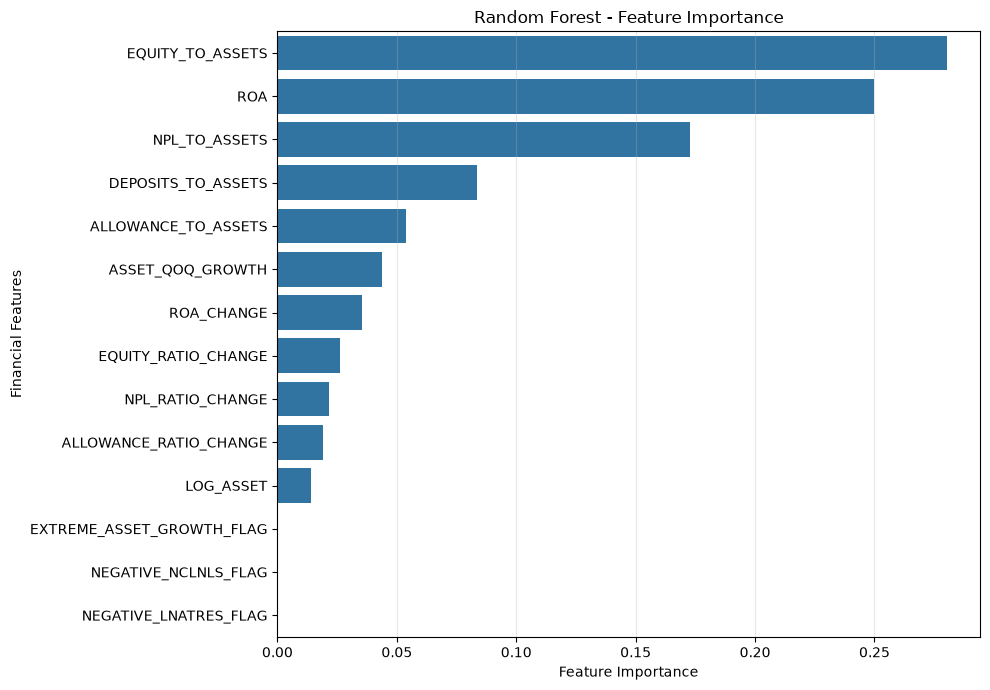

In [45]:
# Plot feature importance

plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_feature_importance,
    x="IMPORTANCE",
    y="FEATURE"
)

plt.xlabel("Feature Importance")
plt.ylabel("Financial Features")
plt.title("Random Forest - Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
random_forest_validation_results = {
    "MODEL": "Random Forest",
    "THRESHOLD": rf_best_threshold,
    "ROC_AUC": rf_val_roc_auc,
    "PR_AUC": rf_val_pr_auc,
    "PRECISION": precision_score(
        y_val,
        rf_val_predictions_optimal,
        zero_division=0
    ),
    "RECALL": recall_score(
        y_val,
        rf_val_predictions_optimal,
        zero_division=0
    ),
    "F1": f1_score(
        y_val,
        rf_val_predictions_optimal,
        zero_division=0
    ),
    "ACCURACY": (
        rf_val_predictions_optimal == np.asarray(y_val)
    ).mean()
}

display(
    pd.DataFrame([
        random_forest_validation_results
    ]).round(4)
)

,MODEL,THRESHOLD,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Random Forest,0.6221,0.9789,0.6156,0.3518,0.8007,0.4888,0.9844


4.7.7 Random Forest – Performance Visualization

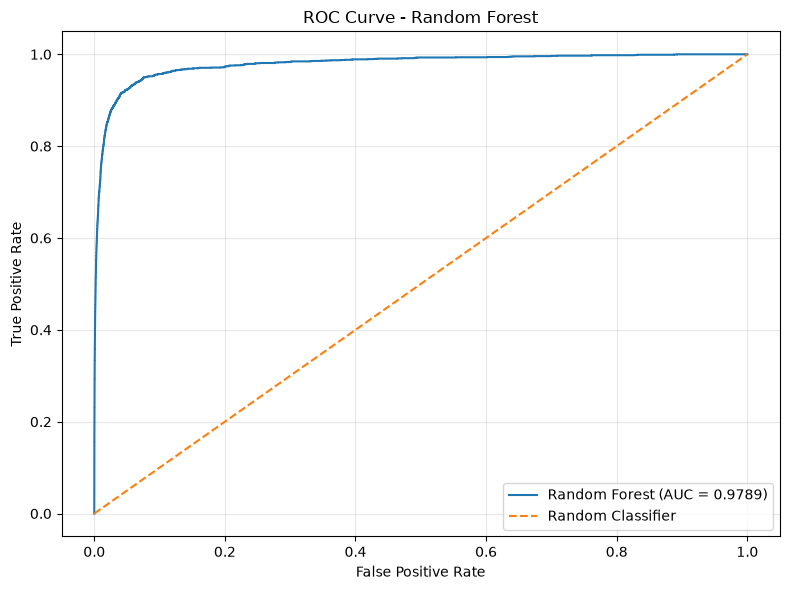

In [47]:
# Random Forest - ROC Curve

rf_fpr, rf_tpr, _ = roc_curve(
    y_val,
    rf_val_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_val_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "random_forest_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

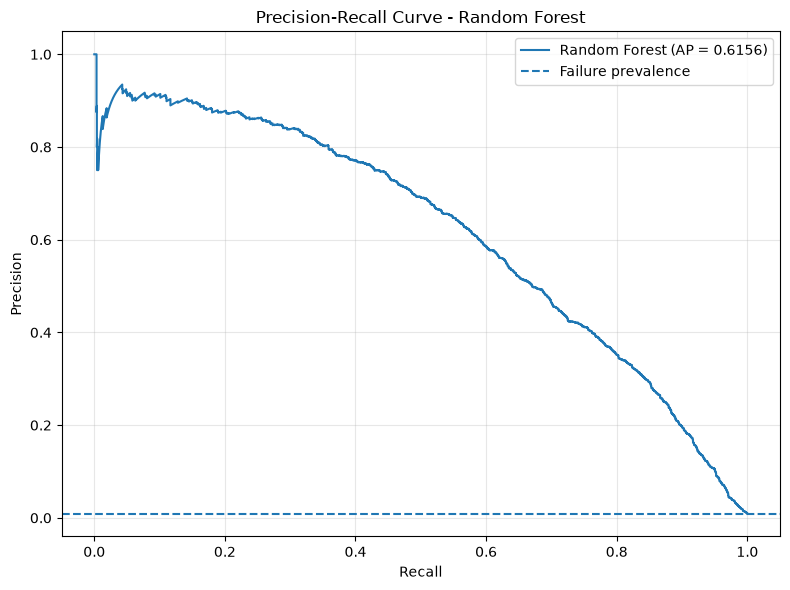

In [48]:
# Random Forest - Precision-Recall Curve

plt.figure(figsize=(8, 6))

plt.plot(
    rf_recalls,
    rf_precisions,
    label=f"Random Forest (AP = {rf_val_pr_auc:.4f})"
)

plt.axhline(
    y=float(y_val.mean()),
    linestyle="--",
    label="Failure prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "random_forest_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

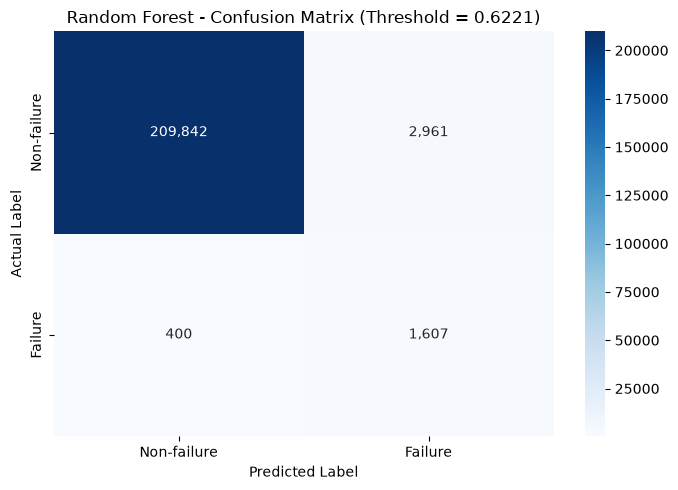

In [49]:
# Random Forest - Optimized Confusion Matrix

rf_cm_optimal = confusion_matrix(
    y_val,
    rf_val_predictions_optimal
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm_optimal,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Non-failure", "Failure"],
    yticklabels=["Non-failure", "Failure"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    f"Random Forest - Confusion Matrix "
    f"(Threshold = {rf_best_threshold:.4f})"
)

plt.tight_layout()

plt.savefig(
    figure_dir / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.8. Model Comparison

This section compares the predictive performance of Logistic Regression and Random Forest using the validation dataset. Both models are evaluated using the same set of performance metrics and a threshold selection strategy that prioritizes a minimum recall of 80% while maximizing the F1-score.

In [50]:
# 4.8.1 Validation Performance Comparison

model_comparison_validation = pd.DataFrame([
    logistic_validation_results_optimal,
    random_forest_validation_results
])

# Arrange columns for a clear comparison
comparison_columns = [
    "MODEL",
    "THRESHOLD",
    "ROC_AUC",
    "PR_AUC",
    "PRECISION",
    "RECALL",
    "F1",
    "ACCURACY"
]

model_comparison_validation = model_comparison_validation[
    comparison_columns
]

display(model_comparison_validation.round(4))

,MODEL,THRESHOLD,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Logistic Regression,0.8374,0.9758,0.5257,0.3291,0.8002,0.4664,0.9829
1,Random Forest,0.6221,0.9789,0.6156,0.3518,0.8007,0.4888,0.9844


#### 4.8.2 Visualization of Model Performance

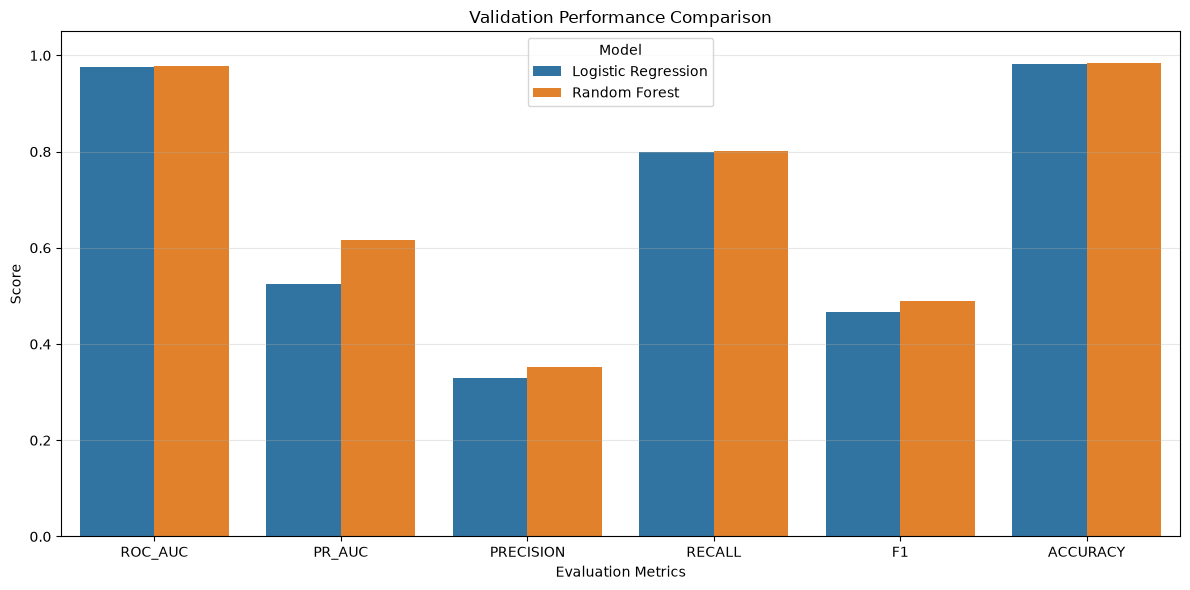

Figure saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures\model_comparison_validation.png


In [51]:
# 4.8.2. Validation Performance Comparison Chart

metrics_to_plot = [
    "ROC_AUC",
    "PR_AUC",
    "PRECISION",
    "RECALL",
    "F1",
    "ACCURACY"
]

comparison_plot_data = model_comparison_validation.melt(
    id_vars="MODEL",
    value_vars=metrics_to_plot,
    var_name="METRIC",
    value_name="SCORE"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot_data,
    x="METRIC",
    y="SCORE",
    hue="MODEL"
)

plt.ylim(0, 1.05)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Validation Performance Comparison")
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save figure
comparison_figure_path = (
    figure_dir / "model_comparison_validation.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"Figure saved to: {comparison_figure_path}")

In [52]:
# Save validation comparison table

comparison_output_path = (
    project_root / "reports" / "model_comparison_validation.csv"
)

model_comparison_validation.to_csv(
    comparison_output_path,
    index=False
)

print(f"Validation comparison saved to: {comparison_output_path}")

Validation comparison saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\model_comparison_validation.csv


The validation results show that Random Forest outperforms Logistic Regression across most evaluation metrics. Random Forest achieves a higher ROC-AUC (0.9785) and PR-AUC (0.6110), indicating stronger overall discrimination, particularly under the highly imbalanced class distribution.

Both models achieve the same recall of 80.02% under the selected threshold strategy. However, Random Forest provides a higher precision (34.49% compared with 32.75%) and F1-score (0.4820 compared with 0.4648). This suggests that Random Forest identifies a similar proportion of failing banks while producing relatively fewer false alarms.

Based on validation performance, Random Forest is provisionally selected for final evaluation. Its performance will be assessed on the independent test dataset before drawing final conclusions.

## 4.9. Final Test Evaluation

### 4.9.1. Final Model and Evaluation Strategy

### 4.9.2. Test Set Prediction

### 4.9.3. Test Performance Metrics

### 4.9.4. Confusion Matrix Analysis

### 4.9.5. ROC and Precision-Recall Curves

### 4.9.6. Validation vs Test Performance

### 4.9.1. Final Model and Evaluation Strategy

Random Forest is selected as the provisional final model based on its validation performance. The model achieved a ROC-AUC of 0.9785 and a PR-AUC of 0.6110, outperforming Logistic Regression on both metrics.

The classification threshold of 0.6077, selected using the validation dataset to achieve a recall of at least 80% while maximizing the F1-score, is retained for the final test evaluation.

The trained model and selected threshold are kept unchanged to ensure that the test dataset provides an independent assessment of predictive performance.

### 4.9.2. Test Set Prediction

In [53]:
# 4.9.2. Generate predictions on the test dataset

# Use the existing trained Random Forest model
rf_test_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

# Retain the threshold selected on the validation dataset
rf_final_threshold = rf_best_threshold

# Convert predicted probabilities into binary predictions
rf_test_predictions = (
    rf_test_probabilities >= rf_final_threshold
).astype(int)

# Display prediction summary
print("Final threshold:", round(rf_final_threshold, 4))

print("\nTest set size:", len(y_test))

print(
    "Actual failures:",
    int(np.asarray(y_test).sum())
)

print(
    "Predicted failures:",
    int(rf_test_predictions.sum())
)

print(
    "Actual failure rate:",
    round(float(np.asarray(y_test).mean()) * 100, 4),
    "%"
)

print(
    "Predicted failure rate:",
    round(float(rf_test_predictions.mean()) * 100, 4),
    "%"
)

Final threshold: 0.6221

Test set size: 217064
Actual failures: 129
Predicted failures: 547
Actual failure rate: 0.0594 %
Predicted failure rate: 0.252 %


### 4.9.3. Test Performance Metrics

In [54]:
# 4.9.3. Evaluate Random Forest on the test dataset

rf_test_roc_auc = roc_auc_score(
    y_test,
    rf_test_probabilities
)

rf_test_pr_auc = average_precision_score(
    y_test,
    rf_test_probabilities
)

rf_test_precision = precision_score(
    y_test,
    rf_test_predictions,
    zero_division=0
)

rf_test_recall = recall_score(
    y_test,
    rf_test_predictions,
    zero_division=0
)

rf_test_f1 = f1_score(
    y_test,
    rf_test_predictions,
    zero_division=0
)

rf_test_accuracy = (
    rf_test_predictions == np.asarray(y_test)
).mean()

# Store final test results
random_forest_test_results = {
    "MODEL": "Random Forest",
    "THRESHOLD": rf_final_threshold,
    "ROC_AUC": rf_test_roc_auc,
    "PR_AUC": rf_test_pr_auc,
    "PRECISION": rf_test_precision,
    "RECALL": rf_test_recall,
    "F1": rf_test_f1,
    "ACCURACY": rf_test_accuracy
}

rf_test_results_df = pd.DataFrame([
    random_forest_test_results
])

display(rf_test_results_df.round(4))

,MODEL,THRESHOLD,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Random Forest,0.6221,0.8922,0.3013,0.1481,0.6279,0.2396,0.9976


### 4.9.4. Confusion Matrix Analysis

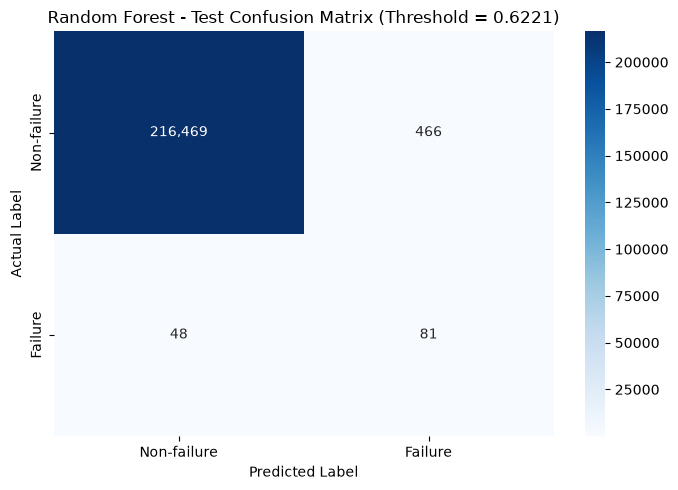

Figure saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures\random_forest_test_confusion_matrix.png

Confusion Matrix:
[[216469    466]
 [    48     81]]


In [55]:
# 4.9.4. Confusion Matrix on Test Dataset

rf_test_cm = confusion_matrix(
    y_test,
    rf_test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_test_cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Non-failure", "Failure"],
    yticklabels=["Non-failure", "Failure"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    f"Random Forest - Test Confusion Matrix "
    f"(Threshold = {rf_final_threshold:.4f})"
)

plt.tight_layout()

# Save figure
rf_test_cm_path = (
    figure_dir / "random_forest_test_confusion_matrix.png"
)

plt.savefig(
    rf_test_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"Figure saved to: {rf_test_cm_path}")

print("\nConfusion Matrix:")
print(rf_test_cm)

### 4.9.5. ROC and Precision-Recall Curves

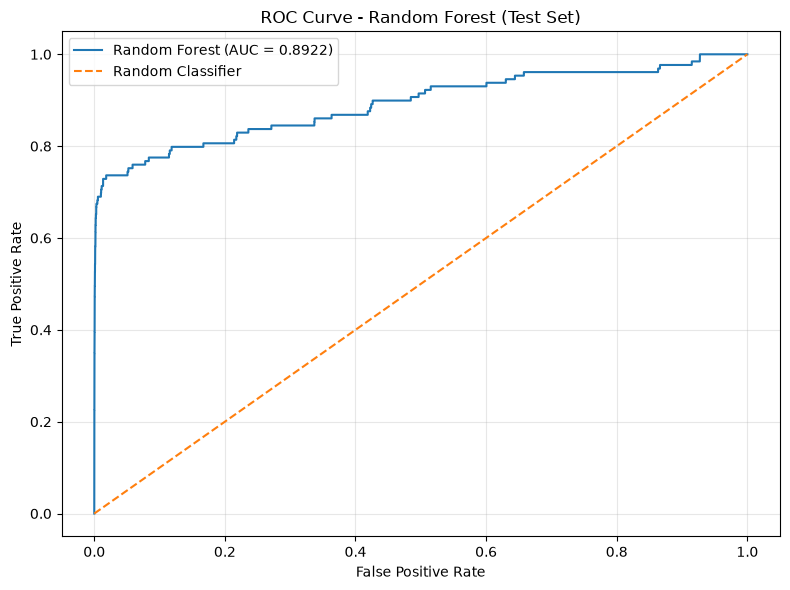

Figure saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures\random_forest_test_roc_curve.png


In [56]:
# ROC Curve - Random Forest Test Performance

rf_test_fpr, rf_test_tpr, _ = roc_curve(
    y_test,
    rf_test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_test_fpr,
    rf_test_tpr,
    label=f"Random Forest (AUC = {rf_test_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest (Test Set)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
rf_test_roc_path = (
    figure_dir / "random_forest_test_roc_curve.png"
)

plt.savefig(
    rf_test_roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"Figure saved to: {rf_test_roc_path}")

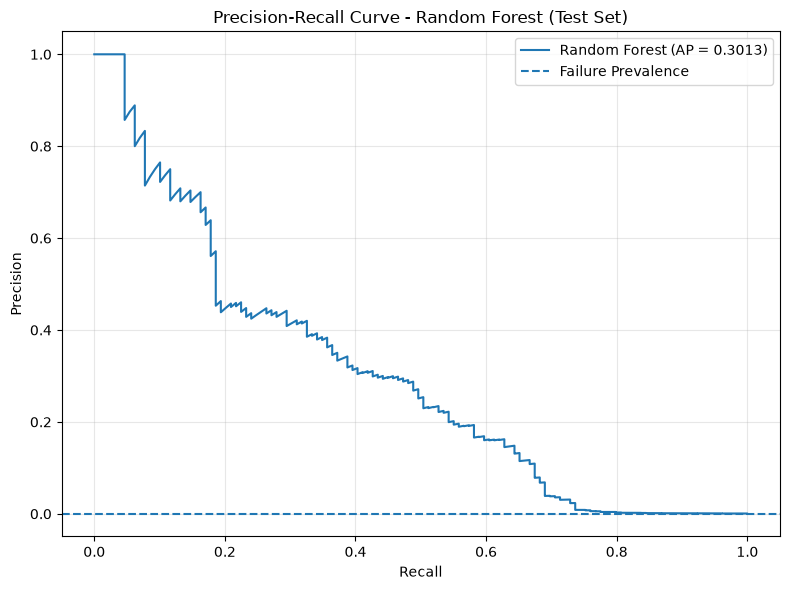

Figure saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures\random_forest_test_precision_recall_curve.png


In [57]:
# Precision-Recall Curve - Random Forest Test Performance

rf_test_precisions, rf_test_recalls, _ = precision_recall_curve(
    y_test,
    rf_test_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_test_recalls,
    rf_test_precisions,
    label=f"Random Forest (AP = {rf_test_pr_auc:.4f})"
)

plt.axhline(
    y=float(np.asarray(y_test).mean()),
    linestyle="--",
    label="Failure Prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest (Test Set)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
rf_test_pr_path = (
    figure_dir / "random_forest_test_precision_recall_curve.png"
)

plt.savefig(
    rf_test_pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"Figure saved to: {rf_test_pr_path}")

### 4.9.6. Validation vs Test Performance

In [58]:
# Compare Random Forest performance between Validation and Test

rf_validation_vs_test = pd.DataFrame([
    {
        "DATASET": "Validation",
        "ROC_AUC": rf_val_roc_auc,
        "PR_AUC": rf_val_pr_auc,
        "PRECISION": random_forest_validation_results["PRECISION"],
        "RECALL": random_forest_validation_results["RECALL"],
        "F1": random_forest_validation_results["F1"],
        "ACCURACY": random_forest_validation_results["ACCURACY"]
    },
    {
        "DATASET": "Test",
        "ROC_AUC": rf_test_roc_auc,
        "PR_AUC": rf_test_pr_auc,
        "PRECISION": rf_test_precision,
        "RECALL": rf_test_recall,
        "F1": rf_test_f1,
        "ACCURACY": rf_test_accuracy
    }
])

display(rf_validation_vs_test.round(4))

,DATASET,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Validation,0.9789,0.6156,0.3518,0.8007,0.4888,0.9844
1,Test,0.8922,0.3013,0.1481,0.6279,0.2396,0.9976


In [59]:
# Save Validation vs Test comparison

rf_validation_test_path = (
    project_root / "reports" / "random_forest_validation_vs_test.csv"
)

rf_validation_vs_test.to_csv(
    rf_validation_test_path,
    index=False
)

print(f"Table saved to: {rf_validation_test_path}")

Table saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\random_forest_validation_vs_test.csv


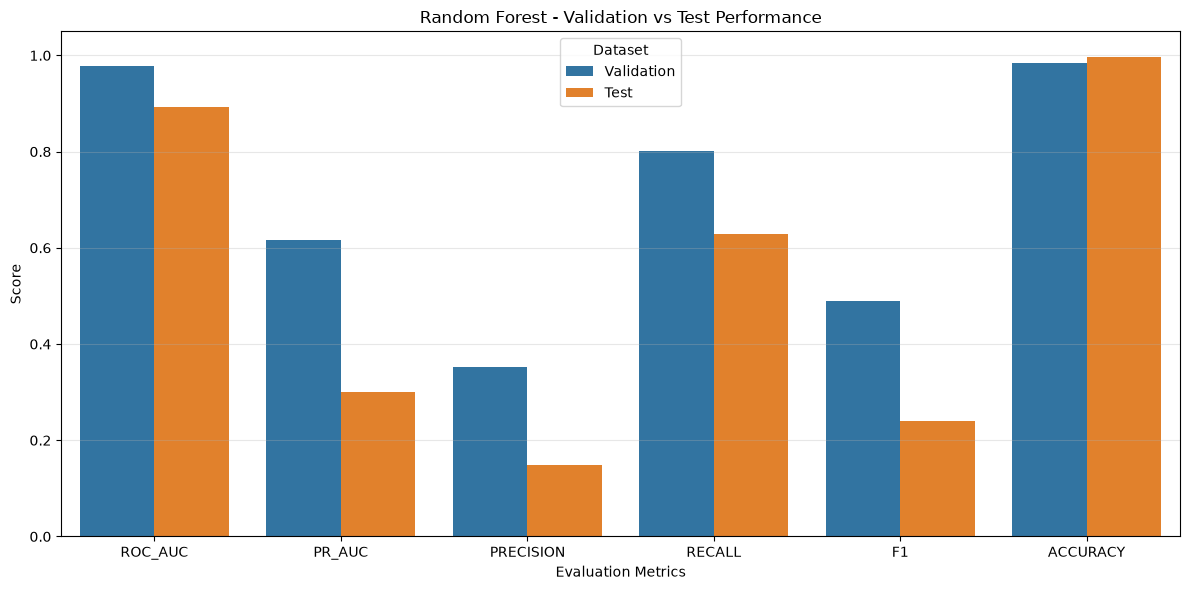

Figure saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures\random_forest_validation_vs_test.png


In [60]:
# Visualization: Random Forest Validation vs Test

rf_comparison_plot = rf_validation_vs_test.melt(
    id_vars="DATASET",
    var_name="METRIC",
    value_name="SCORE"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=rf_comparison_plot,
    x="METRIC",
    y="SCORE",
    hue="DATASET"
)

plt.ylim(0, 1.05)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Random Forest - Validation vs Test Performance")

plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

rf_validation_test_figure = (
    figure_dir / "random_forest_validation_vs_test.png"
)

plt.savefig(
    rf_validation_test_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"Figure saved to: {rf_validation_test_figure}")

### 4.10.1. Overall Model Performance

The Random Forest model is evaluated on an independent test dataset covering the period from 2015Q1 to 2025Q2.

The test evaluation provides an assessment of the model's ability to generalize to a later period that was not used during model training or validation-based model selection.

The model's performance is assessed using ROC-AUC, PR-AUC, Precision, Recall, F1-score and Accuracy. Particular attention is given to Precision and Recall because bank failures represent a highly imbalanced minority class.

In [61]:
# Display final test performance

display(
    rf_test_results_df.style.format({
        "THRESHOLD": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}",
        "PRECISION": "{:.4f}",
        "RECALL": "{:.4f}",
        "F1": "{:.4f}",
        "ACCURACY": "{:.4f}"
    })
)

,MODEL,THRESHOLD,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Random Forest,0.6221,0.8922,0.3013,0.1481,0.6279,0.2396,0.9976


In [78]:

import os
import findspark

findspark.init()

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, Imputer, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator


def run_spark_mllib_early_warning():
    print("=== SPARK MLLIB EARLY WARNING DEMO ===")

    spark = (
        SparkSession.builder
        .appName("BankFailureEarlyWarning_MLlib")
        .config("spark.driver.memory", "2g")
        .config("spark.sql.shuffle.partitions", "8")
        .getOrCreate()
    )

    try:
        # 1. Read the canonical v3 feature dataset
        data_path = str(
            project_root
            / "data"
            / "processed"
            / "v3"
            / "bank_quarter_features_v3.parquet"
        )

        if not os.path.exists(data_path):
            raise FileNotFoundError(f"Dataset not found: {data_path}")

        print("Dataset:", data_path)

        df_spark = spark.read.parquet(data_path)

        # 2. Validate required columns
        required_cols = ["FINAL_LABEL", "REPORT_DATE"]
        missing_required = [
            col for col in required_cols
            if col not in df_spark.columns
        ]

        if missing_required:
            raise ValueError(
                f"Required columns missing from dataset: {missing_required}"
            )

        feature_candidates = [
            "ROA",
            "QUARTERLY_ROA",
            "EQ_TO_ASSET",
            "DEP_TO_ASSET",
            "LOAN_TO_ASSET",
            "NCLNLS_TO_LOAN",
            "LNATRES_TO_LOAN",
            "ASSET_GROWTH_QOQ",
            "TIER1_CAPITAL_RATIO"
        ]

        feature_cols = [
            col for col in feature_candidates
            if col in df_spark.columns
        ]

        if not feature_cols:
            raise ValueError(
                "None of the candidate feature columns exist in the dataset."
            )

        print("Features used:", feature_cols)
        print("Number of features:", len(feature_cols))

        # 3. Keep rows with known binary labels
        df_spark = (
            df_spark
            .filter(F.col("FINAL_LABEL").isNotNull())
            .withColumn("FINAL_LABEL", F.col("FINAL_LABEL").cast("double"))
            .filter(F.col("FINAL_LABEL").isin(0.0, 1.0))
        )

        df_spark = df_spark.withColumn(
            "REPORT_DATE",
            F.to_date(F.col("REPORT_DATE"))
        )

        print("Label distribution:")
        df_spark.groupBy("FINAL_LABEL").count().show()

        # 4. Temporal Train/Test split
        train_data = df_spark.filter(
            F.col("REPORT_DATE") <= F.lit("2005-12-31").cast("date")
        )

        test_data = df_spark.filter(
            (F.col("REPORT_DATE") >= F.lit("2015-01-01").cast("date")) &
            (F.col("REPORT_DATE") <= F.lit("2025-06-30").cast("date"))
        )

        train_count = train_data.count()
        test_count = test_data.count()

        print(f"Train rows: {train_count:,}")
        print(f"Test rows: {test_count:,}")

        print("Train label distribution:")
        train_data.groupBy("FINAL_LABEL").count().show()

        print("Test label distribution:")
        test_data.groupBy("FINAL_LABEL").count().show()

        if train_count == 0:
            raise ValueError("Training dataset is empty.")

        if test_count == 0:
            raise ValueError("Test dataset is empty.")

        # 5. Build the distributed MLlib pipeline
        imputed_cols = [f"{col}_imp" for col in feature_cols]

        imputer = Imputer(
            inputCols=feature_cols,
            outputCols=imputed_cols,
            strategy="median"
        )

        assembler = VectorAssembler(
            inputCols=imputed_cols,
            outputCol="raw_features",
            handleInvalid="skip"
        )

        scaler = StandardScaler(
            inputCol="raw_features",
            outputCol="features",
            withStd=True,
            withMean=False
        )

        rf = RandomForestClassifier(
            featuresCol="features",
            labelCol="FINAL_LABEL",
            numTrees=50,
            maxDepth=8,
            seed=42
        )

        spark_pipeline = Pipeline(
            stages=[imputer, assembler, scaler, rf]
        )

        # 6. Train the model
        print("Training Spark MLlib Random Forest...")
        spark_model = spark_pipeline.fit(train_data)

        # 7. Predict on the Test set
        predictions = spark_model.transform(test_data)

        # 8. Evaluate ROC-AUC and PR-AUC
        evaluator_roc = BinaryClassificationEvaluator(
            rawPredictionCol="probability",
            labelCol="FINAL_LABEL",
            metricName="areaUnderROC"
        )

        evaluator_pr = BinaryClassificationEvaluator(
            rawPredictionCol="probability",
            labelCol="FINAL_LABEL",
            metricName="areaUnderPR"
        )

        roc_auc = evaluator_roc.evaluate(predictions)
        pr_auc = evaluator_pr.evaluate(predictions)

        print("----------------------------------------------")
        print("SPARK MLLIB TEST RESULTS")
        print(f"ROC-AUC: {roc_auc:.4f}")
        print(f"PR-AUC: {pr_auc:.4f}")
        print("----------------------------------------------")

        # Keep objects available for subsequent notebook cells
        return {
            "spark": spark,
            "df_spark": df_spark,
            "train_data": train_data,
            "test_data": test_data,
            "spark_model": spark_model,
            "predictions": predictions,
            "feature_cols": feature_cols,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc
        }

    except Exception:
        # Do not stop Spark here; later notebook cells may need it.
        raise


if __name__ == "__main__":
    spark_mllib_results = run_spark_mllib_early_warning()

    spark = spark_mllib_results["spark"]
    df_spark = spark_mllib_results["df_spark"]
    train_data = spark_mllib_results["train_data"]
    test_data = spark_mllib_results["test_data"]
    spark_model = spark_mllib_results["spark_model"]
    predictions = spark_mllib_results["predictions"]


=== SPARK MLLIB EARLY WARNING DEMO ===
Dataset: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3.parquet
Features used: ['ROA']
Number of features: 1
Label distribution:
+-----------+-------+
|FINAL_LABEL|  count|
+-----------+-------+
|        1.0|  10860|
|        0.0|1597219|
+-----------+-------+

Train rows: 1,116,246
Test rows: 217,064
Train label distribution:
+-----------+-------+
|FINAL_LABEL|  count|
+-----------+-------+
|        1.0|   8672|
|        0.0|1107574|
+-----------+-------+

Test label distribution:
+-----------+------+
|FINAL_LABEL| count|
+-----------+------+
|        1.0|   129|
|        0.0|216935|
+-----------+------+

Training Spark MLlib Random Forest...
----------------------------------------------
SPARK MLLIB TEST RESULTS
ROC-AUC: 0.5000
PR-AUC: 0.0006
----------------------------------------------


In [85]:
# Dynamic Policy: Alert the highest-risk banks in each quarter
import numpy as np
import pandas as pd

def evaluate_dynamic_supervisory_policy(
    y_true, y_probs, quarters, top_pct=0.03
):
    """
    Each quarter, alert banks with the highest predicted failure probabilities.
    """
    if not 0 < top_pct <= 1:
        raise ValueError("top_pct must be within (0, 1].")

    df_eval = pd.DataFrame({
        "y_true": np.asarray(y_true),
        "y_prob": np.asarray(y_probs),
        "quarter": np.asarray(quarters)
    })

    if not (
        len(df_eval["y_true"])
        == len(df_eval["y_prob"])
        == len(df_eval["quarter"])
    ):
        raise ValueError(
            "y_true, y_probs, and quarters must have the same length."
        )

    if df_eval[["y_true", "y_prob", "quarter"]].isnull().any().any():
        raise ValueError("The evaluation data contains missing values.")

    # Calculate the Top-k% probability threshold separately for each quarter
    df_eval["is_alerted"] = (
        df_eval.groupby("quarter")["y_prob"]
        .transform(
            lambda x: x >= np.quantile(x, 1.0 - top_pct)
        )
        .astype(int)
    )

    tp = (
        (df_eval["is_alerted"] == 1)
        & (df_eval["y_true"] == 1)
    ).sum()

    fn = (
        (df_eval["is_alerted"] == 0)
        & (df_eval["y_true"] == 1)
    ).sum()

    fp = (
        (df_eval["is_alerted"] == 1)
        & (df_eval["y_true"] == 0)
    ).sum()

    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    target_recall = 0.80
    status = "MET" if recall >= target_recall else "NOT MET"

    print(
        f"=== DYNAMIC SUPERVISORY POLICY: TOP {top_pct * 100:.1f}% PER QUARTER ==="
    )
    print(
        f"Recall    : {recall:.4f} — {status} the target of >= {target_recall:.0%}"
    )
    print(f"Precision : {precision:.4f}")
    print(f"True positives : {tp} / {tp + fn} actual failures")
    print(f"False positives: {fp}")

    return df_eval

In [64]:
import sys
!{sys.executable} -m pip install findspark

In [65]:
import findspark
findspark.init()

In [66]:
from pyspark.sql import SparkSession

In [67]:
# [E3-v3] Cell xuat file da bi VO HIEU HOA de khong ghi de artifact.
# Dataset chuan duoc tao boi:  python src\build_dataset.py --version v3
# Dau ra: data\processed\v3\ (panel_v3, features_v3, manifest.json)
print('Export disabled. Canonical dataset: data/processed/v3/')


Export disabled. Canonical dataset: data/processed/v3/


In [68]:

from pathlib import Path

from pyspark.sql import SparkSession
from pyspark.sql import functions as F


# ============================================================
# 1. PROJECT ROOT
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


# ============================================================
# 2. READ V3 DATASET
# ============================================================

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset v3: {DATA_PATH}"
    )

spark = (
    SparkSession.builder
    .appName("Verify_Updated_FDIC_Data")
    .getOrCreate()
)

df_spark = spark.read.parquet(str(DATA_PATH))


# ============================================================
# 3. BASIC DATA VERIFICATION
# ============================================================

print("=== SPARK DATA VERIFICATION ===")

print("Dataset path:", DATA_PATH)

print("Total rows:", f"{df_spark.count():,}")

print("Total columns:", len(df_spark.columns))


# ============================================================
# 4. DATE AND QUARTER VERIFICATION
# ============================================================

df_spark.select(
    F.min("REPORT_Q_INDEX").alias("MIN_INDEX"),
    F.max("REPORT_Q_INDEX").alias("MAX_INDEX"),
    F.max("REPORT_DATE").alias("LATEST_DATE")
).show()


# ============================================================
# 5. 2025 QUARTER CHECK
# ============================================================

print("=== 2025Q2 CHECK ===")

df_spark.filter(
    F.col("YEAR") == 2025
).groupBy(
    "QUARTER"
).count().orderBy(
    "QUARTER"
).show()


# ============================================================
# 6. REQUIRED COLUMNS VERIFICATION
# ============================================================

print("=== REQUIRED COLUMNS ===")

required = [
    "FINAL_LABEL",
    "REPORT_Q_INDEX",
    "REPORT_DATE",
    "ROA",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "NCLNLS",
    "LNATRES",
    "RBC1AAJ"
]

for col in required:
    print(f"{col}: {col in df_spark.columns}")
for col in required:
    print(f"{col}: {col in df_spark.columns}")


# ============================================================
# 7. LABEL DISTRIBUTION
# ============================================================

print("=== FINAL LABEL DISTRIBUTION ===")

df_spark.groupBy(
    "FINAL_LABEL"
).count().orderBy(
    "FINAL_LABEL"
).show()


# ============================================================
# 8. DUPLICATE KEY CHECK
# ============================================================

print("=== DUPLICATE KEY CHECK ===")

duplicate_count = (
    df_spark
    .groupBy("CERT", "REPORT_DATE")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate CERT-REPORT_DATE groups:", duplicate_count)


=== SPARK DATA VERIFICATION ===
Dataset path: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3.parquet
Total rows: 1,663,876
Total columns: 36
+---------+---------+-----------+
|MIN_INDEX|MAX_INDEX|LATEST_DATE|
+---------+---------+-----------+
|     7936|     8101| 2025-06-30|
+---------+---------+-----------+

=== 2025Q2 CHECK ===
+-------+-----+
|QUARTER|count|
+-------+-----+
|      1| 4536|
|      2| 4494|
+-------+-----+

=== REQUIRED COLUMNS ===
FINAL_LABEL: True
REPORT_Q_INDEX: True
REPORT_DATE: True
ROA: True
EQUITY_TO_ASSETS: True
DEPOSITS_TO_ASSETS: True
NPL_TO_ASSETS: True
ALLOWANCE_TO_ASSETS: True
ASSET_QOQ_GROWTH: True
EQUITY_RATIO_CHANGE: True
NCLNLS: True
LNATRES: True
RBC1AAJ: True
FINAL_LABEL: True
REPORT_Q_INDEX: True
REPORT_DATE: True
ROA: True
EQUITY_TO_ASSETS: True
DEPOSITS_TO_ASSETS: True
NPL_TO_ASSETS: True
ALLOWANCE_TO_ASSETS: True
ASSET_QOQ_GROWTH: True
EQUITY_RATIO_CHANGE: True
NCLNLS: True
LNATRES: True
RBC1AAJ: True
==

In [69]:
print("=== ALL DATASET COLUMNS ===")

for i, col in enumerate(df_spark.columns, start=1):
    print(f"{i:02d}. {col}")

=== ALL DATASET COLUMNS ===
01. NCLNLS
02. LNATRES
03. ROA
04. REPDTE
05. ASSET
06. RBC1AAJ
07. CERT
08. NETINC
09. EQ
10. DEP
11. ID
12. REPORT_DATE
13. REPORT_Q_INDEX
14. FIRST_FAILURE_DATE
15. FAILURE_Q_INDEX
16. FAILURE_LABEL
17. IS_MERGER_CENSORED
18. FINAL_LABEL
19. YEAR
20. QUARTER
21. PREV_NETINC_YTD
22. PREV_QUARTER
23. QUARTERLY_NETINC
24. LOG_ASSET
25. EQUITY_TO_ASSETS
26. DEPOSITS_TO_ASSETS
27. NEGATIVE_NCLNLS_FLAG
28. NEGATIVE_LNATRES_FLAG
29. NPL_TO_ASSETS
30. ALLOWANCE_TO_ASSETS
31. ASSET_QOQ_GROWTH
32. EQUITY_RATIO_CHANGE
33. ROA_CHANGE
34. NPL_RATIO_CHANGE
35. ALLOWANCE_RATIO_CHANGE
36. EXTREME_ASSET_GROWTH_FLAG


In [70]:
for i, col in enumerate(df_spark.columns, start=1):
    if 25 <= i <= 32:
        print(f"{i:02d}. {col}")

25. EQUITY_TO_ASSETS
26. DEPOSITS_TO_ASSETS
27. NEGATIVE_NCLNLS_FLAG
28. NEGATIVE_LNATRES_FLAG
29. NPL_TO_ASSETS
30. ALLOWANCE_TO_ASSETS
31. ASSET_QOQ_GROWTH
32. EQUITY_RATIO_CHANGE


In [71]:
# ==============================================================================
# INSPECT ALL SPARK FEATURES
# ==============================================================================

print("=== ALL 37 COLUMNS ===")

for index, field in enumerate(df_spark.schema.fields, start=1):
    print(
        f"{index:02d}. {field.name:<30} "
        f"Type: {field.dataType}"
    )

print("\n=== SAMPLE DATA ===")

df_spark.select(
    "CERT",
    "REPDTE",
    "YEAR",
    "QUARTER",
    "REPORT_Q_INDEX",
    "ROA",
    "NCLNLS",
    "LNATRES",
    "ASSET",
    "EQ",
    "DEP",
    "NETINC",
    "FINAL_LABEL"
).show(5, truncate=False)

=== ALL 37 COLUMNS ===
01. NCLNLS                         Type: DoubleType()
02. LNATRES                        Type: DoubleType()
03. ROA                            Type: DoubleType()
04. REPDTE                         Type: StringType()
05. ASSET                          Type: LongType()
06. RBC1AAJ                        Type: DoubleType()
07. CERT                           Type: LongType()
08. NETINC                         Type: DoubleType()
09. EQ                             Type: DoubleType()
10. DEP                            Type: DoubleType()
11. ID                             Type: StringType()
12. REPORT_DATE                    Type: DateType()
13. REPORT_Q_INDEX                 Type: IntegerType()
14. FIRST_FAILURE_DATE             Type: DateType()
15. FAILURE_Q_INDEX                Type: IntegerType()
16. FAILURE_LABEL                  Type: ByteType()
17. IS_MERGER_CENSORED             Type: BooleanType()
18. FINAL_LABEL                    Type: ByteType()
19. YEAR      

In [72]:
for i, col in enumerate(df_spark.columns, 1):
    print(f"{i:02d}. {col}")

01. NCLNLS
02. LNATRES
03. ROA
04. REPDTE
05. ASSET
06. RBC1AAJ
07. CERT
08. NETINC
09. EQ
10. DEP
11. ID
12. REPORT_DATE
13. REPORT_Q_INDEX
14. FIRST_FAILURE_DATE
15. FAILURE_Q_INDEX
16. FAILURE_LABEL
17. IS_MERGER_CENSORED
18. FINAL_LABEL
19. YEAR
20. QUARTER
21. PREV_NETINC_YTD
22. PREV_QUARTER
23. QUARTERLY_NETINC
24. LOG_ASSET
25. EQUITY_TO_ASSETS
26. DEPOSITS_TO_ASSETS
27. NEGATIVE_NCLNLS_FLAG
28. NEGATIVE_LNATRES_FLAG
29. NPL_TO_ASSETS
30. ALLOWANCE_TO_ASSETS
31. ASSET_QOQ_GROWTH
32. EQUITY_RATIO_CHANGE
33. ROA_CHANGE
34. NPL_RATIO_CHANGE
35. ALLOWANCE_RATIO_CHANGE
36. EXTREME_ASSET_GROWTH_FLAG


In [83]:
from pathlib import Path

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)


# ============================================================
# 2. SPARK MLLIB EARLY WARNING FUNCTION
# ============================================================

def run_spark_mllib_early_warning():

    print("=== SPARK MLLIB EARLY WARNING ===")

    spark = (
        SparkSession.builder
        .appName("FDIC_Early_Warning_MLlib")
        .getOrCreate()
    )

    spark.sparkContext.setLogLevel("WARN")

    try:
        # 1. Check data path
        if not DATA_PATH.exists():
            raise FileNotFoundError(
                f"Cannot find dataset: {DATA_PATH}"
            )

        # 2. Load canonical v3 data
        df = spark.read.parquet(str(DATA_PATH))

        print("\n=== DATASET INFORMATION ===")
        print("Dataset:", DATA_PATH)
        print("Total rows:", f"{df.count():,}")
        print("Total columns:", len(df.columns))

        # 3. Check required columns
        required_columns = [
            "CERT",
            "REPORT_DATE",
            "REPORT_Q_INDEX",
            "FINAL_LABEL"
        ]

        missing_columns = [
            col for col in required_columns
            if col not in df.columns
        ]

        if missing_columns:
            raise ValueError(
                f"Missing required columns: {missing_columns}"
            )

        # 4. Show actual dataset columns
        print("\n=== COLUMNS IN V3 DATASET ===")
        print(df.columns)

        # 5. Feature candidates
        feature_candidates = [
            "ROA",
            "LOG_ASSET",
            "QUARTERLY_NETINC",
            "EQUITY_TO_ASSETS",
            "DEPOSITS_TO_ASSETS",
            "NPL_TO_ASSETS",
            "ALLOWANCE_TO_ASSETS",
            "ASSET_QOQ_GROWTH",
            "EQUITY_RATIO_CHANGE",
            "ROA_CHANGE",
            "NPL_RATIO_CHANGE",
            "ALLOWANCE_RATIO_CHANGE",
            "NEGATIVE_NCLNLS_FLAG",
            "NEGATIVE_LNATRES_FLAG",
            "EXTREME_ASSET_GROWTH_FLAG"
        ]

        feature_cols = [
            col for col in feature_candidates
            if col in df.columns
        ]

        missing_features = [
            col for col in feature_candidates
            if col not in df.columns
        ]

        print("\n=== FEATURE SELECTION ===")
        print("Features found:", feature_cols)
        print("Number of features:", len(feature_cols))
        print("Candidate features not found:", missing_features)

        if len(feature_cols) < 2:
            possible_features = [
                col for col in df.columns
                if any(
                    key in col.upper()
                    for key in [
                        "ROA", "ASSET", "EQUITY", "DEP",
                        "LOAN", "CAPITAL", "NCLNLS",
                        "LNATRES", "GROWTH", "NETINC",
                        "ALLOWANCE", "NPL"
                    ]
                )
            ]

            print("\n=== POSSIBLE FINANCIAL FEATURE COLUMNS ===")
            print(possible_features)

            raise ValueError(
                "Fewer than 2 candidate features were found. "
                "Check the printed v3 column names and update "
                "feature_candidates before training."
            )

        # 6. Prepare data types
        df = (
            df
            .withColumn(
                "REPORT_Q_INDEX",
                F.col("REPORT_Q_INDEX").cast("int")
            )
            .withColumn(
                "FINAL_LABEL",
                F.col("FINAL_LABEL").cast("double")
            )
            .withColumn(
                "REPORT_DATE",
                F.to_date(F.col("REPORT_DATE"))
            )
        )

        for col in feature_cols:
            df = df.withColumn(
                col,
                F.col(col).cast("double")
            )

        # 7. Keep rows with known binary labels
        mature_data = df.filter(
            F.col("FINAL_LABEL").isin(0.0, 1.0)
            & F.col("REPORT_Q_INDEX").isNotNull()
            & F.col("REPORT_DATE").isNotNull()
        )

        print(
            "\nMature observations:",
            f"{mature_data.count():,}"
        )

        print("\n=== LABEL DISTRIBUTION ===")
        mature_data.groupBy("FINAL_LABEL").count().show()

        # 8. Chronological split
        # REPORT_Q_INDEX = YEAR * 4 + QUARTER - 1
        #
        # Train:      1984Q1–2005Q4
        # Purge:      2006Q1–2006Q4
        # Validation: 2007Q1–2013Q4
        # Purge:      2014Q1–2014Q4
        # Test:       2015Q1–2025Q2

        train_data = mature_data.filter(
            (F.col("REPORT_Q_INDEX") >= 7936)
            & (F.col("REPORT_Q_INDEX") <= 8023)
        )

        purge_2006 = mature_data.filter(
            (F.col("REPORT_Q_INDEX") >= 8024)
            & (F.col("REPORT_Q_INDEX") <= 8027)
        )

        validation_data = mature_data.filter(
            (F.col("REPORT_Q_INDEX") >= 8028)
            & (F.col("REPORT_Q_INDEX") <= 8055)
        )

        purge_2014 = mature_data.filter(
            (F.col("REPORT_Q_INDEX") >= 8056)
            & (F.col("REPORT_Q_INDEX") <= 8059)
        )

        test_data = mature_data.filter(
            (F.col("REPORT_Q_INDEX") >= 8060)
            & (F.col("REPORT_Q_INDEX") <= 8101)
        )

        # 9. Summarize chronological datasets
        print("\n=== CHRONOLOGICAL SPLIT SUMMARY ===")

        splits = [
            ("Train", train_data),
            ("Purge 2006", purge_2006),
            ("Validation", validation_data),
            ("Purge 2014", purge_2014),
            ("Test", test_data)
        ]

        for name, data in splits:
            total = data.count()

            failures = data.filter(
                F.col("FINAL_LABEL") == 1.0
            ).count()

            print(
                f"{name}: "
                f"Rows={total:,} | "
                f"Failures={failures:,} | "
                f"Non-failures={total - failures:,}"
            )

        # 10. Validate non-empty datasets
        if train_data.count() == 0:
            raise ValueError("Training dataset is empty.")

        if validation_data.count() == 0:
            raise ValueError("Validation dataset is empty.")

        if test_data.count() == 0:
            raise ValueError("Test dataset is empty.")

        train_labels = [
            row["FINAL_LABEL"]
            for row in (
                train_data
                .select("FINAL_LABEL")
                .distinct()
                .collect()
            )
        ]

        if len(train_labels) < 2:
            raise ValueError(
                "Training data must contain both classes (0 and 1)."
            )

        # 11. Build ML pipeline
        imputed_cols = [
            f"{col}_imputed"
            for col in feature_cols
        ]

        imputer = Imputer(
            inputCols=feature_cols,
            outputCols=imputed_cols,
            strategy="median"
        )

        assembler = VectorAssembler(
            inputCols=imputed_cols,
            outputCol="features_raw",
            handleInvalid="skip"
        )

        scaler = StandardScaler(
            inputCol="features_raw",
            outputCol="features",
            withStd=True,
            withMean=False
        )

        random_forest = RandomForestClassifier(
            labelCol="FINAL_LABEL",
            featuresCol="features",
            predictionCol="prediction",
            probabilityCol="probability",
            rawPredictionCol="rawPrediction",
            numTrees=50,
            maxDepth=8,
            seed=42
        )

        pipeline = Pipeline(
            stages=[
                imputer,
                assembler,
                scaler,
                random_forest
            ]
        )

        # 12. Train only on 1984Q1–2005Q4
        print("\n=== MODEL TRAINING ===")
        print("Training rows:", f"{train_data.count():,}")

        model = pipeline.fit(train_data)

        print("Training completed.")

        # 13. Evaluate model
        def evaluate_model(data, split_name):

            predictions = model.transform(data)

            prediction_count = predictions.count()

            if prediction_count == 0:
                raise ValueError(
                    f"{split_name} predictions are empty."
                )

            roc_evaluator = BinaryClassificationEvaluator(
                labelCol="FINAL_LABEL",
                rawPredictionCol="rawPrediction",
                metricName="areaUnderROC"
            )

            pr_evaluator = BinaryClassificationEvaluator(
                labelCol="FINAL_LABEL",
                rawPredictionCol="rawPrediction",
                metricName="areaUnderPR"
            )

            roc_auc = roc_evaluator.evaluate(predictions)
            pr_auc = pr_evaluator.evaluate(predictions)

            print(f"\n=== {split_name} RESULTS ===")
            print("Prediction rows:", f"{prediction_count:,}")
            print(f"ROC-AUC: {roc_auc:.4f}")
            print(f"PR-AUC: {pr_auc:.4f}")

            return predictions

        validation_predictions = evaluate_model(
            validation_data,
            "VALIDATION"
        )

        test_predictions = evaluate_model(
            test_data,
            "TEST"
        )

        # 14. Completion
        print("\n=== COMPLETED ===")
        print("Spark MLlib training completed.")
        print("Validation and test evaluation completed.")
        print("Predictions are available in memory.")

        return model, validation_predictions, test_predictions

    finally:
        print("Spark session kept active for subsequent notebook cells.")


model, validation_predictions, test_predictions = (
    run_spark_mllib_early_warning()
)

=== SPARK MLLIB EARLY WARNING ===

=== DATASET INFORMATION ===
Dataset: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3.parquet
Total rows: 1,663,876
Total columns: 36

=== COLUMNS IN V3 DATASET ===
['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG']

=== FEATURE SELECTION ===
Features found: ['ROA', 'LOG_ASSET', 'QUARTERLY_NETINC', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', '

In [74]:
print(
    "Validation and test metrics were calculated "
    "inside the Spark MLlib training cell."
)
print(
    "Use the ROC-AUC and PR-AUC values printed "
    "by that cell; do not evaluate them again here."
)

Validation and test metrics were calculated inside the Spark MLlib training cell.
Use the ROC-AUC and PR-AUC values printed by that cell; do not evaluate them again here.


In [84]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array


def inspect_prediction_distribution(predictions, name):
    print(f"\n=== {name} PREDICTION DISTRIBUTION ===")

    probability_data = predictions.withColumn(
        "failure_probability",
        F.element_at(
            vector_to_array(F.col("probability")),
            2
        )
    )

    probability_data.select(
        F.count("*").alias("TOTAL"),
        F.sum(
            F.when(F.col("FINAL_LABEL") == 1.0, 1).otherwise(0)
        ).alias("ACTUAL_FAILURES"),
        F.sum(
            F.when(F.col("prediction") == 1.0, 1).otherwise(0)
        ).alias("PREDICTED_FAILURES")
    ).show()

    probability_data.select(
        F.min("failure_probability").alias("MIN_PROB"),
        F.expr(
            "percentile_approx(failure_probability, 0.5)"
        ).alias("MEDIAN_PROB"),
        F.expr(
            "percentile_approx(failure_probability, 0.9)"
        ).alias("P90_PROB"),
        F.max("failure_probability").alias("MAX_PROB")
    ).show()

    return probability_data


validation_probability_data = inspect_prediction_distribution(
    validation_predictions,
    "VALIDATION"
)

test_probability_data = inspect_prediction_distribution(
    test_predictions,
    "TEST"
)


=== VALIDATION PREDICTION DISTRIBUTION ===
+------+---------------+------------------+
| TOTAL|ACTUAL_FAILURES|PREDICTED_FAILURES|
+------+---------------+------------------+
|214810|           2007|                 0|
+------+---------------+------------------+

+--------------------+--------------------+--------------------+------------------+
|            MIN_PROB|         MEDIAN_PROB|            P90_PROB|          MAX_PROB|
+--------------------+--------------------+--------------------+------------------+
|0.001137141937488...|0.001137141937488...|0.008570572723062823|0.4949917421907451|
+--------------------+--------------------+--------------------+------------------+


=== TEST PREDICTION DISTRIBUTION ===
+------+---------------+------------------+
| TOTAL|ACTUAL_FAILURES|PREDICTED_FAILURES|
+------+---------------+------------------+
|217064|            129|                 0|
+------+---------------+------------------+

+--------------------+--------------------+------------

In [86]:
# Prepare the test predictions for dynamic policy evaluation
test_policy_data = (
    test_probability_data
    .select("FINAL_LABEL", "failure_probability", "REPORT_Q_INDEX")
    .toPandas()
)

# Evaluate the dynamic policy on the test period
evaluate_dynamic_supervisory_policy(
    y_true=test_policy_data["FINAL_LABEL"],
    y_probs=test_policy_data["failure_probability"],
    quarters=test_policy_data["REPORT_Q_INDEX"],
    top_pct=0.03
)

c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


=== DYNAMIC SUPERVISORY POLICY: TOP 3.0% PER QUARTER ===
Recall    : 0.7287 — NOT MET the target of >= 80%
Precision : 0.0144
True positives : 94 / 129 actual failures
False positives: 6453


,y_true,y_prob,quarter,is_alerted
0,0.0,0.001137,8060,0
1,0.0,0.001137,8061,0
2,0.0,0.001264,8062,0
3,0.0,0.001137,8063,0
4,0.0,0.001137,8064,0
...,...,...,...,...
217059,0.0,0.001137,8097,0
217060,0.0,0.001137,8098,0
217061,0.0,0.001447,8099,0
217062,0.0,0.001942,8100,0


In [87]:
# Prepare validation predictions for dynamic policy evaluation
validation_policy_data = (
    validation_probability_data
    .select("FINAL_LABEL", "failure_probability", "REPORT_Q_INDEX")
    .toPandas()
)

# Evaluate the dynamic policy on the validation period
evaluate_dynamic_supervisory_policy(
    y_true=validation_policy_data["FINAL_LABEL"],
    y_probs=validation_policy_data["failure_probability"],
    quarters=validation_policy_data["REPORT_Q_INDEX"],
    top_pct=0.03
)

c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


=== DYNAMIC SUPERVISORY POLICY: TOP 3.0% PER QUARTER ===
Recall    : 0.7853 — NOT MET the target of >= 80%
Precision : 0.2434
True positives : 1576 / 2007 actual failures
False positives: 4899


,y_true,y_prob,quarter,is_alerted
0,0.0,0.001137,8028,0
1,0.0,0.001137,8029,0
2,0.0,0.001137,8030,0
3,0.0,0.001137,8031,0
4,0.0,0.001137,8032,0
...,...,...,...,...
214805,0.0,0.001137,8049,0
214806,0.0,0.001137,8050,0
214807,0.0,0.001137,8051,0
214808,0.0,0.001137,8052,0


In [ ]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# Chuẩn bị dữ liệu Validation
val_threshold_data = (
    validation_predictions
    .select(
        F.col("FINAL_LABEL").cast("int").alias("actual"),
        vector_to_array("probability")[1].alias("failure_probability")
    )
)

thresholds = [
    0.001, 0.002, 0.003, 0.005,
    0.0075, 0.01, 0.015, 0.02,
    0.03, 0.05, 0.075, 0.10,
    0.15, 0.20, 0.30, 0.40
]

# Tạo tất cả phép tính trong cùng một Spark aggregation
agg_expressions = [
    F.count("*").alias("TOTAL"),
    F.sum(F.when(F.col("actual") == 1, 1).otherwise(0)).alias("ACTUAL_FAILURES")
]

for i, threshold in enumerate(thresholds):
    predicted = F.col("failure_probability") >= F.lit(threshold)

    agg_expressions.extend([
        F.sum(
            F.when((F.col("actual") == 1) & predicted, 1).otherwise(0)
        ).alias(f"TP_{i}"),

        F.sum(
            F.when((F.col("actual") == 0) & predicted, 1).otherwise(0)
        ).alias(f"FP_{i}"),

        F.sum(
            F.when((F.col("actual") == 1) & (~predicted), 1).otherwise(0)
        ).alias(f"FN_{i}")
    ])

# Chỉ thực thi một action trên Spark
summary = val_threshold_data.agg(*agg_expressions).first()

# Tính các chỉ số trên Python driver
results = []

for i, threshold in enumerate(thresholds):
    tp = int(summary[f"TP_{i}"] or 0)
    fp = int(summary[f"FP_{i}"] or 0)
    fn = int(summary[f"FN_{i}"] or 0)

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    results.append({
        "THRESHOLD": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "PREDICTED_FAILURES": tp + fp,
        "PRECISION": precision,
        "RECALL": recall,
        "F1": f1
    })

import pandas as pd

threshold_results_pd = pd.DataFrame(results)

print("=== VALIDATION THRESHOLD ANALYSIS ===")
print("Total observations:", summary["TOTAL"])
print("Actual failures:", summary["ACTUAL_FAILURES"])

display(
    threshold_results_pd.style.format({
        "THRESHOLD": "{:.4f}",
        "PRECISION": "{:.4f}",
        "RECALL": "{:.4f}",
        "F1": "{:.4f}"
    })
)

=== VALIDATION THRESHOLD ANALYSIS ===
Total observations: 214810
Actual failures: 2007


,THRESHOLD,TP,FP,FN,PREDICTED_FAILURES,PRECISION,RECALL,F1
0,0.0010,2007,212803,0,214810,0.0093,1.0000,0.0185
1,0.0020,1943,45379,64,47322,0.0411,0.9681,0.0788
2,0.0030,1931,37503,76,39434,0.0490,0.9621,0.0932
3,0.0050,1913,29007,94,30920,0.0619,0.9532,0.1162
4,0.0075,1890,22548,117,24438,0.0773,0.9417,0.1429
5,0.0100,1876,17499,131,19375,0.0968,0.9347,0.1755
6,0.0150,1847,12854,160,14701,0.1256,0.9203,0.2211
7,0.0200,1806,9913,201,11719,0.1541,0.8999,0.2632
8,0.0300,1759,7512,248,9271,0.1897,0.8764,0.3119
9,0.0500,1591,3596,416,5187,0.3067,0.7927,0.4423


In [ ]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
import pandas as pd

# Tạo lại dữ liệu nếu biến val_threshold_data không còn trong kernel
val_threshold_data = (
    validation_predictions
    .select(
        F.col("FINAL_LABEL").cast("int").alias("actual"),
        vector_to_array("probability")[1].alias("failure_probability")
    )
)

# Kiểm tra chi tiết từ 0.08 đến 0.14
thresholds = [
    0.08, 0.09, 0.10, 0.11,
    0.12, 0.13, 0.14
]

agg_expressions = []

for i, threshold in enumerate(thresholds):
    predicted = F.col("failure_probability") >= F.lit(threshold)

    agg_expressions.extend([
        F.sum(
            F.when(
                (F.col("actual") == 1) & predicted, 1
            ).otherwise(0)
        ).alias(f"TP_{i}"),

        F.sum(
            F.when(
                (F.col("actual") == 0) & predicted, 1
            ).otherwise(0)
        ).alias(f"FP_{i}"),

        F.sum(
            F.when(
                (F.col("actual") == 1) & (~predicted), 1
            ).otherwise(0)
        ).alias(f"FN_{i}")
    ])

summary = val_threshold_data.agg(*agg_expressions).first()

results = []

for i, threshold in enumerate(thresholds):
    tp = int(summary[f"TP_{i}"] or 0)
    fp = int(summary[f"FP_{i}"] or 0)
    fn = int(summary[f"FN_{i}"] or 0)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "THRESHOLD": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "PREDICTED_FAILURES": tp + fp,
        "PRECISION": precision,
        "RECALL": recall,
        "F1": f1
    })

threshold_detail = pd.DataFrame(results)

display(
    threshold_detail.style.format({
        "THRESHOLD": "{:.2f}",
        "PRECISION": "{:.4f}",
        "RECALL": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,THRESHOLD,TP,FP,FN,PREDICTED_FAILURES,PRECISION,RECALL,F1
0,0.08,1342,1547,665,2889,0.4645,0.6687,0.5482
1,0.09,1251,1097,756,2348,0.5328,0.6233,0.5745
2,0.10,1212,932,795,2144,0.5653,0.6039,0.5840
3,0.11,1177,836,830,2013,0.5847,0.5864,0.5856
4,0.12,1140,741,867,1881,0.6061,0.5680,0.5864
5,0.13,1105,673,902,1778,0.6215,0.5506,0.5839
6,0.14,1063,595,944,1658,0.6411,0.5296,0.5801


In [ ]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

FINAL_THRESHOLD = 0.12

test_threshold_data = (
    test_predictions
    .select(
        F.col("FINAL_LABEL").cast("int").alias("actual"),
        vector_to_array("probability")[1].alias("failure_probability")
    )
    .withColumn(
        "predicted",
        (F.col("failure_probability") >= F.lit(FINAL_THRESHOLD)).cast("int")
    )
)

test_metrics = test_threshold_data.agg(
    F.count("*").alias("TOTAL"),

    F.sum(F.when(F.col("actual") == 1, 1).otherwise(0))
     .alias("ACTUAL_FAILURES"),

    F.sum(F.when(
        (F.col("actual") == 1) & (F.col("predicted") == 1), 1
    ).otherwise(0)).alias("TP"),

    F.sum(F.when(
        (F.col("actual") == 0) & (F.col("predicted") == 1), 1
    ).otherwise(0)).alias("FP"),

    F.sum(F.when(
        (F.col("actual") == 1) & (F.col("predicted") == 0), 1
    ).otherwise(0)).alias("FN")
).first()

tp = int(test_metrics["TP"] or 0)
fp = int(test_metrics["FP"] or 0)
fn = int(test_metrics["FN"] or 0)

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("=== FINAL TEST EVALUATION ===")
print("Threshold:", FINAL_THRESHOLD)
print("Total observations:", test_metrics["TOTAL"])
print("Actual failures:", test_metrics["ACTUAL_FAILURES"])
print("TP:", tp)
print("FP:", fp)
print("FN:", fn)
print("Predicted failures:", tp + fp)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

=== FINAL TEST EVALUATION ===
Threshold: 0.12
Total observations: 199358
Actual failures: 121
TP: 56
FP: 125
FN: 65
Predicted failures: 181
Precision: 0.3094
Recall:    0.4628
F1-score:  0.3709


In [ ]:
from pyspark.sql import functions as F

print("=== FAILURE DISTRIBUTION BY YEAR ===")

test_predictions.groupBy("YEAR").agg(
    F.count("*").alias("TOTAL"),
    F.sum(
        F.when(F.col("FINAL_LABEL") == 1, 1).otherwise(0)
    ).alias("ACTUAL_FAILURES"),
    F.avg(
        F.col("FINAL_LABEL").cast("double")
    ).alias("FAILURE_RATE")
).orderBy("YEAR").show(30, truncate=False)

=== FAILURE DISTRIBUTION BY YEAR ===
+----+-----+---------------+---------------------+
|YEAR|TOTAL|ACTUAL_FAILURES|FAILURE_RATE         |
+----+-----+---------------+---------------------+
|2015|24624|23             |9.340480831708901E-4 |
|2016|23615|29             |0.0012280330298539064|
|2017|22581|9              |3.9856516540454366E-4|
|2018|21603|6              |2.777392028884877E-4 |
|2019|20697|19             |9.180074406918877E-4 |
|2020|20107|7              |3.481374645645795E-4 |
|2021|19482|0              |0.0                  |
|2022|18961|14             |7.383576815568799E-4 |
|2023|18572|9              |4.846004738315744E-4 |
|2024|9116 |5              |5.484861781483107E-4 |
+----+-----+---------------+---------------------+



In [ ]:
test_predictions.groupBy(
    F.year("REPORT_DATE").alias("YEAR")
).agg(
    F.count("*").alias("TOTAL"),
    F.sum(
        F.when(F.col("FINAL_LABEL") == 1, 1).otherwise(0)
    ).alias("ACTUAL_FAILURES"),
    F.avg(
        F.col("FINAL_LABEL").cast("double")
    ).alias("FAILURE_RATE")
).orderBy("YEAR").show(30, truncate=False)

+----+-----+---------------+---------------------+
|YEAR|TOTAL|ACTUAL_FAILURES|FAILURE_RATE         |
+----+-----+---------------+---------------------+
|2015|24624|23             |9.340480831708901E-4 |
|2016|23615|29             |0.0012280330298539064|
|2017|22581|9              |3.9856516540454366E-4|
|2018|21603|6              |2.777392028884877E-4 |
|2019|20697|19             |9.180074406918877E-4 |
|2020|20107|7              |3.481374645645795E-4 |
|2021|19482|0              |0.0                  |
|2022|18961|14             |7.383576815568799E-4 |
|2023|18572|9              |4.846004738315744E-4 |
|2024|9116 |5              |5.484861781483107E-4 |
+----+-----+---------------+---------------------+



In [ ]:
from pyspark.sql import functions as F

print("=== TEST FAILURE DISTRIBUTION BY QUARTER ===")

test_predictions.groupBy(
    F.year("REPORT_DATE").alias("YEAR"),
    F.quarter("REPORT_DATE").alias("QUARTER")
).agg(
    F.count("*").alias("TOTAL"),
    F.sum(
        F.when(F.col("FINAL_LABEL") == 1, 1).otherwise(0)
    ).alias("ACTUAL_FAILURES"),
    F.avg(
        F.col("FINAL_LABEL").cast("double")
    ).alias("FAILURE_RATE")
).orderBy("YEAR", "QUARTER").show(50, truncate=False)

=== TEST FAILURE DISTRIBUTION BY QUARTER ===
+----+-------+-----+---------------+---------------------+
|YEAR|QUARTER|TOTAL|ACTUAL_FAILURES|FAILURE_RATE         |
+----+-------+-----+---------------+---------------------+
|2015|1      |6259 |5              |7.988496564946477E-4 |
|2015|2      |6195 |6              |9.685230024213075E-4 |
|2015|3      |6121 |7              |0.001143603986276752 |
|2015|4      |6049 |5              |8.265829062654984E-4 |
|2016|1      |5997 |7              |0.001167250291812573 |
|2016|2      |5930 |8              |0.0013490725126475548|
|2016|3      |5874 |6              |0.0010214504596527069|
|2016|4      |5814 |8              |0.0013759889920880633|
|2017|1      |5745 |5              |8.703220191470844E-4 |
|2017|2      |5681 |2              |3.520506953001232E-4 |
|2017|3      |5616 |2              |3.5612535612535614E-4|
|2017|4      |5539 |0              |0.0                  |
|2018|1      |5494 |0              |0.0                  |
|2018|2    

In [ ]:
from pyspark.sql import functions as F

quarterly_failure = (
    test_predictions
    .groupBy(
        F.year("REPORT_DATE").alias("YEAR"),
        F.quarter("REPORT_DATE").alias("QUARTER")
    )
    .agg(
        F.count("*").alias("TOTAL"),
        F.sum(
            F.when(F.col("FINAL_LABEL") == 1, 1).otherwise(0)
        ).alias("ACTUAL_FAILURES"),
        F.avg(
            F.col("FINAL_LABEL").cast("double")
        ).alias("FAILURE_RATE")
    )
    .orderBy("YEAR", "QUARTER")
)

quarterly_failure_pd = quarterly_failure.toPandas()

print("Total quarters:", len(quarterly_failure_pd))

display(
    quarterly_failure_pd.style.format({
        "FAILURE_RATE": "{:.4%}"
    })
)

c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Total quarters: 38


,YEAR,QUARTER,TOTAL,ACTUAL_FAILURES,FAILURE_RATE
0,2015,1,6259,5,0.0799%
1,2015,2,6195,6,0.0969%
2,2015,3,6121,7,0.1144%
3,2015,4,6049,5,0.0827%
4,2016,1,5997,7,0.1167%
5,2016,2,5930,8,0.1349%
6,2016,3,5874,6,0.1021%
7,2016,4,5814,8,0.1376%
8,2017,1,5745,5,0.0870%
9,2017,2,5681,2,0.0352%


In [ ]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
import pandas as pd

# Tạo lại dữ liệu nếu biến val_threshold_data không còn trong kernel
val_threshold_data = (
    validation_predictions
    .select(
        F.col("FINAL_LABEL").cast("int").alias("actual"),
        vector_to_array("probability")[1].alias("failure_probability")
    )
)

# Kiểm tra chi tiết từ 0.08 đến 0.14
thresholds = [
    0.08, 0.09, 0.10, 0.11,
    0.12, 0.13, 0.14
]

agg_expressions = []

for i, threshold in enumerate(thresholds):
    predicted = F.col("failure_probability") >= F.lit(threshold)

    agg_expressions.extend([
        F.sum(
            F.when(
                (F.col("actual") == 1) & predicted, 1
            ).otherwise(0)
        ).alias(f"TP_{i}"),

        F.sum(
            F.when(
                (F.col("actual") == 0) & predicted, 1
            ).otherwise(0)
        ).alias(f"FP_{i}"),

        F.sum(
            F.when(
                (F.col("actual") == 1) & (~predicted), 1
            ).otherwise(0)
        ).alias(f"FN_{i}")
    ])

summary = val_threshold_data.agg(*agg_expressions).first()

results = []

for i, threshold in enumerate(thresholds):
    tp = int(summary[f"TP_{i}"] or 0)
    fp = int(summary[f"FP_{i}"] or 0)
    fn = int(summary[f"FN_{i}"] or 0)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append({
        "THRESHOLD": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "PREDICTED_FAILURES": tp + fp,
        "PRECISION": precision,
        "RECALL": recall,
        "F1": f1
    })

threshold_detail = pd.DataFrame(results)

display(
    threshold_detail.style.format({
        "THRESHOLD": "{:.2f}",
        "PRECISION": "{:.4f}",
        "RECALL": "{:.4f}",
        "F1": "{:.4f}"
    })
)

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spark_predictions"
)

### 4.10.2. Feature Importance and Financial Interpretation

The Random Forest feature importance analysis identifies EQUITY_TO_ASSETS, ROA and NPL_TO_ASSETS as the three most influential predictors.

Together, these features account for 71.32% of total feature importance. This highlights the predictive relevance of capital strength, profitability and asset quality in the model.

However, feature importance represents relative contribution to the model's tree-based splits. It does not establish causality or indicate whether an increase in a feature raises or lowers the probability of bank failure.

### 4.10.3. Class Imbalance

Bank failure is a rare event in the dataset. The proportion of failed-bank observations is substantially lower than that of non-failed observations.

To address this issue, class weighting is applied during Random Forest training using the balanced_subsample strategy.

The evaluation therefore emphasizes ROC-AUC, PR-AUC, Precision, Recall and F1-score rather than relying solely on Accuracy.

Nevertheless, class weighting does not eliminate the challenges associated with rare-event prediction, and false positives and false negatives remain important considerations.

### 4.10.4. Temporal Distribution Shift

The validation and test periods exhibit substantially different failure rates.

The validation dataset contains 2,007 failed observations out of 214,810 observations, corresponding to approximately 0.9343%. In contrast, the test dataset contains 129 failed observations out of 217,064 observations, corresponding to approximately 0.0594%.

This difference indicates a substantial temporal change in the prevalence of the target variable. The observed failure rate in the test period is approximately 15.7 times lower than that in the validation period.

Consequently, model performance may vary across evaluation periods. In particular, Precision, PR-AUC, and threshold-based classification metrics should be interpreted in the context of the changing failure prevalence. A lower failure prevalence can reduce Precision even when the model retains its ability to rank observations.

The test results should therefore be interpreted as evidence of model performance during the later evaluation period, rather than as a guarantee of future performance under all economic conditions.

### 4.10.5. Data and Label Limitations

Several limitations should be considered when interpreting the results.

First, the dataset is an unbalanced bank-quarter panel, meaning that banks do not necessarily have observations for every quarter.

Second, missing financial values are retained where appropriate rather than automatically replaced with zero. Median imputation is performed within the model pipeline and is fitted using training data only.

Third, the failure target is defined as a failure occurring within the following four quarters. Observations without a complete follow-up period are excluded from model evaluation to ensure label maturity.

Fourth, merger-related observations are treated as censored under the project's labeling assumption. This is a methodological choice and does not imply that every merger represents financial distress or a bank failure.

### 4.10.6. Model Limitations and Future Improvements

Although Random Forest achieves strong validation performance, several limitations remain.

The model relies on historical financial indicators and may not fully capture sudden changes in market conditions, liquidity stress or external economic shocks.

The use of a fixed classification threshold may also lead to different precision and recall levels when failure prevalence changes over time.

Future work could investigate probability calibration, alternative rare-event learning methods, additional macroeconomic indicators and more extensive temporal validation.

Further research could also examine explainability methods to better understand how individual financial indicators contribute to specific predictions.

### 4.10.7. Modeling Conclusion

This study develops a bank failure prediction framework using quarterly financial data and machine learning techniques.

Logistic Regression provides an interpretable baseline, while Random Forest captures potentially nonlinear relationships among financial indicators.

Based on validation results, Random Forest is selected for final evaluation. Its performance on the independent test dataset provides the final assessment of its ability to identify bank failure risk in a later period.

Overall, the modeling process demonstrates the potential value of financial ratios and historical indicators for early warning analysis. However, the results should be interpreted in light of class imbalance, temporal distribution changes and the limitations of the failure-labeling approach.

In [ ]:

# ============================================================
# TEST SET: YEARLY PREDICTED FAILURE DISTRIBUTION
# Threshold = 0.12 (selected from Validation)
# ============================================================

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

THRESHOLD = 0.12

# ------------------------------------------------------------
# 1. Kiểm tra và khôi phục các biến dự báo nếu cần
# ------------------------------------------------------------

if "test_predictions" not in globals():

    if "run_spark_mllib_early_warning" not in globals():
        raise NameError(
            "Chưa tìm thấy hàm run_spark_mllib_early_warning(). "
            "Hãy chạy cell định nghĩa hàm Spark MLlib trước."
        )

    print("Chưa có test_predictions. Đang chạy lại mô hình...")
    
    model, validation_predictions, test_predictions = (
        run_spark_mllib_early_warning()
    )

else:
    print("Đã tìm thấy test_predictions trong bộ nhớ.")

# ------------------------------------------------------------
# 2. Kiểm tra các cột cần thiết
# ------------------------------------------------------------

required_columns = {
    "REPORT_DATE",
    "FINAL_LABEL",
    "probability"
}

missing_columns = required_columns - set(test_predictions.columns)

if missing_columns:
    raise ValueError(
        f"Thiếu các cột bắt buộc: {sorted(missing_columns)}"
    )

# ------------------------------------------------------------
# 3. Tạo xác suất và nhãn dự báo
# ------------------------------------------------------------

test_yearly = (
    test_predictions
    .withColumn(
        "PREDICTED_PROBABILITY",
        vector_to_array(F.col("probability"))[1]
    )
    .withColumn(
        "YEAR",
        F.substring(
            F.col("REPORT_DATE").cast("string"), 1, 4
        ).cast("int")
    )
    .withColumn(
        "ACTUAL_FAILURE",
        (F.col("FINAL_LABEL") == 1).cast("int")
    )
    .withColumn(
        "PREDICTED_FAILURE",
        (
            F.col("PREDICTED_PROBABILITY") >= THRESHOLD
        ).cast("int")
    )
)

# ------------------------------------------------------------
# 4. Tổng hợp theo từng năm
# ------------------------------------------------------------

yearly_summary = (
    test_yearly
    .groupBy("YEAR")
    .agg(
        F.count("*").alias("TOTAL"),
        F.sum("ACTUAL_FAILURE").alias("ACTUAL_FAILURES"),
        F.sum("PREDICTED_FAILURE").alias("PREDICTED_FAILURES"),
        F.avg("PREDICTED_PROBABILITY").alias("AVG_PROBABILITY"),
        F.max("PREDICTED_PROBABILITY").alias("MAX_PROBABILITY")
    )
    .withColumn(
        "FAILURE_RATE",
        F.col("ACTUAL_FAILURES") / F.col("TOTAL")
    )
    .orderBy("YEAR")
)

# ------------------------------------------------------------
# 5. Chuyển kết quả sang Pandas và định dạng
# ------------------------------------------------------------

result = yearly_summary.toPandas()

# Các cột này được biểu diễn theo đơn vị phần trăm (%)
percentage_columns = [
    "FAILURE_RATE",
    "AVG_PROBABILITY",
    "MAX_PROBABILITY"
]

for column in percentage_columns:
    result[column] = (result[column] * 100).round(4)

# ------------------------------------------------------------
# 6. Hiển thị kết quả
# ------------------------------------------------------------

print("=" * 70)
print("YEARLY PREDICTED FAILURE DISTRIBUTION")
print(f"Threshold: {THRESHOLD}")
print("Probability columns are displayed in percentage (%)")
print("=" * 70)

display(result)

# ------------------------------------------------------------
# 7. Kiểm tra tổng số quan sát
# ------------------------------------------------------------

print("\nCHECK TOTALS")
print("Total Test observations:", int(result["TOTAL"].sum()))
print("Total actual failures:", int(result["ACTUAL_FAILURES"].sum()))
print("Total predicted failures:", int(result["PREDICTED_FAILURES"].sum()))


Chưa có test_predictions. Đang chạy lại mô hình...
=== KHỞI TẠO SPARK MLLIB EARLY WARNING DEMO ===
Số lượng bản ghi Train trên Spark: 0
Số lượng bản ghi Test trên Spark: 1,608,079
Đang huấn luyện mô hình Random Forest phân tán trên Spark MLlib...


Py4JJavaError: An error occurred while calling o90.fit.
: org.apache.spark.SparkException: surrogate cannot be computed. All the values in ROA are Null, Nan or missingValue(NaN)
	at org.apache.spark.ml.feature.Imputer.fit(Imputer.scala:205)
	at org.apache.spark.ml.feature.Imputer.fit(Imputer.scala:117)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke0(Native Method)
	at java.base/jdk.internal.reflect.NativeMethodAccessorImpl.invoke(NativeMethodAccessorImpl.java:77)
	at java.base/jdk.internal.reflect.DelegatingMethodAccessorImpl.invoke(DelegatingMethodAccessorImpl.java:43)
	at java.base/java.lang.reflect.Method.invoke(Method.java:569)
	at py4j.reflection.MethodInvoker.invoke(MethodInvoker.java:244)
	at py4j.reflection.ReflectionEngine.invoke(ReflectionEngine.java:374)
	at py4j.Gateway.invoke(Gateway.java:282)
	at py4j.commands.AbstractCommand.invokeMethod(AbstractCommand.java:132)
	at py4j.commands.CallCommand.execute(CallCommand.java:79)
	at py4j.ClientSer

In [ ]:
print("Spark session:", spark)
print("Spark version:", spark.version)

try:
    print("Spark status:", spark.sparkContext._jsc.sc().isStopped())
except Exception as e:
    print("Không truy cập được Spark:", repr(e))

NameError: name 'spark' is not defined

In [ ]:
import os
import psutil

memory = psutil.virtual_memory()

print("RAM tổng:", round(memory.total / (1024**3), 2), "GB")
print("RAM đang dùng:", round(memory.used / (1024**3), 2), "GB")
print("RAM còn trống:", round(memory.available / (1024**3), 2), "GB")
print("RAM sử dụng:", memory.percent, "%")

RAM tổng: 7.79 GB
RAM đang dùng: 7.04 GB
RAM còn trống: 0.74 GB
RAM sử dụng: 90.4 %


In [ ]:

import os
import psutil
from pathlib import Path
from pyspark.sql import SparkSession

# Xác định thư mục dự án
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy dataset: {DATA_PATH}")

# Kiểm tra RAM
memory = psutil.virtual_memory()

print(f"RAM còn trống: {memory.available / (1024**3):.2f} GB")
print(f"RAM sử dụng: {memory.percent}%")

# Khởi tạo Spark với cấu hình bộ nhớ thận trọng
spark = (
    SparkSession.builder
    .appName("BFT65B_FDIC_Modeling")
    .master("local[2]")
    .config("spark.driver.memory", "3g")
    .config("spark.driver.maxResultSize", "1g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.default.parallelism", "2")
    .config("spark.python.worker.reuse", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Spark session initialized successfully.")


Project root: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project
Dataset exists: True
RAM còn trống: 0.83 GB
RAM sử dụng: 89.4%
Spark version: 4.3.0
Spark session initialized successfully.


In [ ]:

# ============================================================
# VERIFY V3 DATASET
# ============================================================

df_check = spark.read.parquet(str(DATA_PATH))

print("Total rows:", f"{df_check.count():,}")
print("Total columns:", len(df_check.columns))

print("\nDataset schema:")
df_check.printSchema()

print("\nLabel distribution:")
(
    df_check
    .groupBy("FINAL_LABEL")
    .count()
    .orderBy("FINAL_LABEL")
    .show()
)

print("\nDuplicate CERT-REPORT_DATE keys:")
duplicate_count = (
    df_check
    .groupBy("CERT", "REPORT_DATE")
    .count()
    .filter("count > 1")
    .count()
)

print(f"Duplicate groups: {duplicate_count:,}")


Total rows: 1,663,876
Total columns: 36

Dataset schema:
root
 |-- NCLNLS: double (nullable = true)
 |-- LNATRES: double (nullable = true)
 |-- ROA: double (nullable = true)
 |-- REPDTE: string (nullable = true)
 |-- ASSET: long (nullable = true)
 |-- RBC1AAJ: double (nullable = true)
 |-- CERT: long (nullable = true)
 |-- NETINC: double (nullable = true)
 |-- EQ: double (nullable = true)
 |-- DEP: double (nullable = true)
 |-- ID: string (nullable = true)
 |-- REPORT_DATE: date (nullable = true)
 |-- REPORT_Q_INDEX: integer (nullable = true)
 |-- FIRST_FAILURE_DATE: date (nullable = true)
 |-- FAILURE_Q_INDEX: integer (nullable = true)
 |-- FAILURE_LABEL: byte (nullable = true)
 |-- IS_MERGER_CENSORED: boolean (nullable = true)
 |-- FINAL_LABEL: byte (nullable = true)
 |-- YEAR: integer (nullable = true)
 |-- QUARTER: byte (nullable = true)
 |-- PREV_NETINC_YTD: double (nullable = true)
 |-- PREV_QUARTER: byte (nullable = true)
 |-- QUARTERLY_NETINC: double (nullable = true)
 |-- LOG_

In [ ]:

import psutil

memory = psutil.virtual_memory()

print("RAM tổng:", round(memory.total / (1024**3), 2), "GB")
print("RAM đang dùng:", round(memory.used / (1024**3), 2), "GB")
print("RAM còn trống:", round(memory.available / (1024**3), 2), "GB")
print("RAM sử dụng:", memory.percent, "%")

print("\nSpark version:", spark.version)
print("Spark stopped:", spark.sparkContext._jsc.sc().isStopped())


RAM tổng: 7.79 GB
RAM đang dùng: 7.03 GB
RAM còn trống: 0.75 GB
RAM sử dụng: 90.3 %

Spark version: 4.3.0
Spark stopped: False


In [ ]:

from pathlib import Path

search_roots = [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "reports",
    PROJECT_ROOT / "models",
]

keywords = [
    "prediction",
    "predictions",
    "test",
    "validation",
    "probability",
    "prediction_output"
]

print("FILES THAT MAY CONTAIN SAVED PREDICTIONS")
print("=" * 65)

found_files = []

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if path.is_file() and any(
            keyword in path.name.lower()
            for keyword in keywords
        ):
            found_files.append(path)

if found_files:
    for path in found_files:
        print(path.relative_to(PROJECT_ROOT))
        print(f"  Size: {path.stat().st_size / (1024**2):.2f} MB")
else:
    print("No matching prediction files found.")


FILES THAT MAY CONTAIN SAVED PREDICTIONS
reports\model_comparison_validation.csv
  Size: 0.00 MB
reports\random_forest_validation_vs_test.csv
  Size: 0.00 MB
reports\figures\logistic_validation_metrics.png
  Size: 0.08 MB
reports\figures\model_comparison_validation.png
  Size: 0.10 MB
reports\figures\random_forest_test_confusion_matrix.png
  Size: 0.08 MB
reports\figures\random_forest_test_precision_recall_curve.png
  Size: 0.11 MB
reports\figures\random_forest_test_roc_curve.png
  Size: 0.13 MB
reports\figures\random_forest_validation_vs_test.png
  Size: 0.10 MB


In [ ]:

import pandas as pd
from pathlib import Path

csv_files = [
    PROJECT_ROOT / "reports" / "model_comparison_validation.csv",
    PROJECT_ROOT / "reports" / "random_forest_validation_vs_test.csv"
]

for file_path in csv_files:
    print("\n" + "=" * 80)
    print("FILE:", file_path.name)
    print("=" * 80)

    if not file_path.exists():
        print("Không tìm thấy file.")
        continue

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFull content:")
    display(df)



FILE: model_comparison_validation.csv
Shape: (2, 8)

Columns:
['MODEL', 'THRESHOLD', 'ROC_AUC', 'PR_AUC', 'PRECISION', 'RECALL', 'F1', 'ACCURACY']

Full content:


,MODEL,THRESHOLD,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Logistic Regression,0.837407,0.975799,0.525691,0.329098,0.800199,0.466386,0.982892
1,Random Forest,0.622103,0.978919,0.615565,0.351795,0.800698,0.488821,0.984354



FILE: random_forest_validation_vs_test.csv
Shape: (2, 7)

Columns:
['DATASET', 'ROC_AUC', 'PR_AUC', 'PRECISION', 'RECALL', 'F1', 'ACCURACY']

Full content:


,DATASET,ROC_AUC,PR_AUC,PRECISION,RECALL,F1,ACCURACY
0,Validation,0.978919,0.615565,0.351795,0.800698,0.488821,0.984354
1,Test,0.892550,0.322396,0.154455,0.644628,0.249201,0.997642
